# Mouse database v2: what data is available and what is in it

`data_exploration.ipynb` (v1) describes the database but analyses only trail 3. This notebook looks at
**all trails** and at **both exports**: the 2023 pickle `/data/mice/maus.pandas.pkl` (converted from
`maus_mysql.sql`) and the phpMyAdmin dump `mausprojekt-3.sql` of 2025-08-08, converted to
`/data/mice/mausprojekt-3.pandas.pkl` with `tfmplayground/mouse/sql_dump.py`.

* **Part A** compares the two exports and decides which one is the base.
* **Part B** describes all trails of the new export.
* **Part C** checks how usable each trail is for weight forecasting.
* **Part D** looks at the new tables (lab samples, the `Logbuch`) and at columns v1 never used.
* **Part E** summarises data quality and lists candidate datasets for modelling.

No models are trained here. Every number in the text cells is computed in the notebook.

## 0. Setup
The worktree that holds this notebook comes first on `sys.path`, so `tfmplayground` (including the new
`sql_dump.py`) is imported from here and not from the editable install of the main checkout.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent
assert (ROOT / "tfmplayground" / "mouse" / "sql_dump.py").exists(), f"run the notebook from notebooks/ ({ROOT})"
sys.path.insert(0, str(ROOT))

import inspect
import logging
import re
from types import SimpleNamespace
from unittest import mock
from urllib.parse import unquote_plus

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from statsmodels.duration.survfunc import SurvfuncRight

import tfmplayground
from tfmplayground.mouse import michael, preprocessing, sql_dump
from tfmplayground.mouse.preprocessing import PreprocessingConfig
from tfmplayground.mouse.rolling import MIN_CONTEXT, rolling_metrics, rolling_predictions

print("tfmplayground imported from", tfmplayground.__file__)
assert Path(tfmplayground.__file__).resolve().is_relative_to(ROOT)

logging.basicConfig(level=logging.WARNING, format="%(message)s")
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 150)

tfmplayground imported from /workspaces/nanoPFN/src/TFM-Playground/.claude/worktrees/bridge-cse_01Kxsthj9LqeaqKaNs4ZbzvC/tfmplayground/__init__.py


In [2]:
OLD_PATH = sql_dump.OLD_PICKLE  # 2023 export, used by v1 and the results notebooks
NEW_PATH = sql_dump.NEW_PICKLE  # 2025 export, written by `python -m tfmplayground.mouse.sql_dump`
TRAIL = 3  # the trail of the study cohort in v1
COHORT_ROLES = [1, 2, 3]  # RT, RChT, ChT
MIN_MICE = 10  # trails with fewer kept mice are not described one by one in Part C


def config(trails, roles=COHORT_ROLES):
    """v1's configuration (as mouse_with_context.ipynb) for other trails/roles, without sampling."""
    return PreprocessingConfig(trails=list(trails), roles=list(roles), min_length=5, max_weight=100,
                               num_animals=10**9, num_test_animals=10**9, prediction_length=1, seed=0)


def say(text):
    display(Markdown(text))

### English names for the German lookup tables
Names are read from the tables (`Rollen`, `Versuchsreihen`, `Tierversuche`, `Todesursachen`, ...).
v1's English translations are used where they exist; new entries fall back to the German text.

In [3]:
ROLE_NAMES_EN = {
    0: "Unassigned (role 0, not in lookup)", 1: "RT: radiotherapy", 2: "RChT: radiochemotherapy", 3: "ChT: chemotherapy",
    4: "K: control animal at the start", 5: "E: control animal at the end", 6: "V: pilot experiment",
    7: "B: observation without therapy", 8: "KT: no local tumour despite injection, or early termination",
    9: "OP: surgical removal of the primary tumour", 10: "Abort: termination for general condition / spontaneous death",
    11: "NNZ: not yet assigned", 12: "OE: organ removal", 13: "MP: injection of macrophages",
    14: "NP: injection of nanoparticles",
}
DEATH_CAUSES_EN = {
    1: "Unknown", 2: "Experiment ended as planned", 3: "Killed: tumour ulceration", 4: "Killed: poor general condition",
    5: "Spontaneous death", 6: "Unknown: disposed of by animal care", 7: "Poor general condition / suspected lymphoma",
    8: "Death directly after surgery",
}
KILL_METHODS_EN = {1: "CO2", 2: "Cervical dislocation", 3: "Spontaneous death (not killed)", 4: "Final blood sampling",
                   5: "Final ketamine anaesthesia"}
ROUTES_EN = {1: "unknown", 2: "i.p.", 3: "i.a.", 4: "i.v.", 5: "s.c.", 6: "oral gavage"}
PRIMARY_SITES = [1, 2, 3, 13, 14]  # injection sites and the primary tumour (Topographie)
TRAIL_NAMES_EN = {
    1: ("Pilot 1", "dose finding; tolerability; tumour growth"),
    2: ("Cell migration under irradiation", "migration of in-vivo labelled cells into an irradiated area"),
    3: ("Main experiment 1", "effect of RT, ChT, RChT and surgery on metastasis in xenograft models; clonal selection"),
    4: ("Pilot Loges 1", "resistance and bone-marrow micrometastasis under anti-androgen therapy of breast cancer"),
    5: ("Pilot 1 (methods)", "learning methods; animal handling; tumour growth"),
    6: ("Breast cancer model", "tumour-specific radiosensitisation by targeted inhibition of DNA repair"),
    7: ("Nanoparticles", "MRI of tumours; changes due to nanoparticles; changes due to local radiotherapy"),
    8: ("Pilot 1 cell migration", "migration of tumour cells; response to radiotherapy in the luciferase signal"),
    9: ("Pilot 1 olaparib", "effect of olaparib; test of cells and tissues; radiation response of normal tissue"),
    10: ("Main experiment TAS102", "efficacy of TAS102; tolerability; tumour growth"),
    11: ("Pilot N127/2019 PC3", "dose finding; tolerability; tumour growth"),
    12: ("Main experiment N127/2019 PC3", "effect of RT, ChT, RChT and surgery on metastasis; clonal selection"),
    13: ("Pilot N006/2020", "dose finding; tolerability; method test"),
    14: ("Main experiment N006/2020", "immunomodulation in glioblastoma"),
    15: ("Main experiment N052/2020", "response of metastases; response of brain tumours"),
    16: ("Main experiment N029/2023", "cell tracking; abscopal radiation effects; immune reactions"),
    17: ("Pilot N068/2024", "test of the liver tumour model"),
    18: ("Organ removal for ALU-PCR", "tissue for ALU-PCR reference samples"),
}
PROJECT_TITLES_EN = {
    1: "Influence of RT, ChT, simultaneous RChT and surgery on metastasis in xenograft mouse models",
    2: "Selectin-dependent interaction of cell populations in a clinically relevant human tumour model under therapy",
    3: "Resistance and bone-marrow micrometastasis under anti-androgen therapy of breast cancer",
    4: "Role of the TAM receptor family in myeloid leukaemias",
    5: "Pilot with two animals: learning methods",
    6: "Tumour-specific radiosensitisation by targeted inhibition of DNA repair",
    7: "Radiosensitisation of PTEN- or CHD1-depleted prostate carcinomas by PARP1 inhibition",
    8: "TAS102",
    9: "Selectin-dependent interaction of cell populations in a human tumour model under therapy (cell migration)",
    10: "Influence of locally ablative RT, ChT, RChT and surgery on metastasis in two xenograft mouse prostate models",
    11: "Immunomodulation by radiotherapy in glioblastoma",
    12: "Relevance of clonal heterogeneity for cerebral tropism and radiotherapy response of brain tumours",
    13: "Tracking of systemic drugs, nanoparticles and immune cells in a xenograft prostate model with X-ray fluorescence imaging",
    14: "Functional role of small-RNA clusters in hepatocarcinogenesis",
    15: "Organ removal as a supplement to project N029/2023",
}
# Category and content of every table; new tables were described from their columns and sample rows (Part D)
TABLE_INFO = {
    "Versuchstiere": ("core", "one row per mouse: trail, role, sex, strain, birth and death date, cause of death, protocols, batch"),
    "Visiten": ("core", "one row per visit: body weight, relative weight, burden score sheet, tumour volume"),
    "Bestrahlungen": ("treatment", "one row per radiotherapy fraction"),
    "Chemotherapie": ("treatment", "one row per chemotherapy administration"),
    "Operationen": ("treatment", "surgeries (removal of the primary tumour)"),
    "Narkosen": ("treatment", "anaesthesia sessions"),
    "Prozeduren": ("treatment", "free-text clinical procedures (fluids, soft food, ...)"),
    "Tumor": ("outcome", "tumours per mouse: site, cell line, injection and removal date, tumour weight"),
    "Tierversuche": ("design", "approved projects with licence number"),
    "Versuchsreihen": ("design", "trails: name, aims, start/end, project"),
    "Kohorten": ("design", "cohorts: trail x cell line x strain"),
    "VGruppe": ("design", "injection batches: cohort, cell line, date"),
    "Blut": ("lab/sample", "blood samples per mouse: date, running number, remark"),
    "Knochenmark": ("lab/sample", "bone-marrow samples per mouse: date, running number, remark"),
    "Gewebe": ("lab/sample", "tissue taken at necropsy: organ (Topographie), side, date, weight"),
    "Kryo": ("lab/sample", "cryo-preserved samples: sample type and storage position"),
    "Paraffin": ("lab/sample", "paraffin-embedded samples: sample type and storage position"),
    "PCR": ("lab/sample", "ALU-PCR results: cell counts and Cp values per blood/bone-marrow/tissue sample"),
    "PCR_Import": ("lab/sample", "staging table for PCR imports (empty)"),
    "Objekttraeger": ("lab/sample", "microscope slides from paraffin blocks: staining, metastasis counts"),
    "Druckmessungen": ("lab/sample", "pressure measurements (mmHg) per mouse and site"),
    "MRTSequenzen": ("lab/sample", "MRI sequences per mouse"),
    "Logbuch": ("logging", "log of the web application: logins, page views and submitted forms"),
    "Tagescheck": ("admin", "daily quality check of the irradiation device"),
    "Module": ("admin", "menu entries of the web application"),
    "Destinationen": ("admin", "redirect targets of the web application"),
    "SystemVariablen": ("admin", "configuration of the web application"),
}
LOOKUP_TABLES = ["Rollen", "Todesursachen", "Toetungsarten", "Tiertypen", "Tumorzelllinien", "Topographie", "SeitenBez",
                 "RTKonzepte", "ChTKonzepte", "ChemoMed", "Applikation", "Zuechter", "Faerbungen", "Farben", "KlinikFirma",
                 "MRTKontrast", "MRTWichtungen", "Markierungen", "Messkammern", "OTBoxTypen", "OTBoxen",
                 "OTSchnittKonzept", "OTSchnittProzeduren", "Organe", "Organsysteme", "Qualifikationen", "Standorte",
                 "Traeger"]
CATEGORY_ORDER = ["core", "treatment", "outcome", "design", "lab/sample", "logging", "lookup", "admin"]


def table_info(name):
    return TABLE_INFO.get(name, ("lookup", "lookup table") if name in LOOKUP_TABLES else ("other", ""))

### Plot style and helpers (from v1)

In [4]:
INK, MUTED, GRID = "#222222", "#8a8a8a", "#e6e6e3"
THERAPY_COLORS = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a"}
NEW_COLOR = "#eb6834"  # what is new in the 2025 export
plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": "#52514e", "ytick.color": "#52514e", "lines.linewidth": 2, "legend.frameon": False,
    "font.size": 10,
})


def median_iqr(x, digits=0, unit=""):
    """'median [Q1–Q3]' of the non-missing values."""
    x = pd.Series(x, dtype=float).dropna()
    if x.empty:
        return "–"
    q1, med, q3 = x.quantile([0.25, 0.5, 0.75])
    return f"{med:.{digits}f} [{q1:.{digits}f}–{q3:.{digits}f}]{unit}"


def n_pct(count, total):
    return f"{count} ({100 * count / total:.0f}%)" if total else "0"


def join_counts(s):
    """'a 3, b 2' of the values of s."""
    return ", ".join(f"{k} {v}" for k, v in s.dropna().value_counts().items())


def join_unique(s):
    values = s.dropna().unique()
    if pd.api.types.is_numeric_dtype(s):
        values = values.astype(int)
    return ", ".join(map(str, sorted(values)))


def median_line(data, x, y, width=3, min_n=8):
    """Median and IQR over mice in bins of ``width`` days centred on 0; each mouse counts once per bin."""
    per_mouse_bin = data.assign(bin=np.round(data[x] / width) * width).groupby(["bin", "item_id"])[y].mean()
    q = per_mouse_bin.groupby("bin").agg(n="size", q1=lambda v: v.quantile(0.25), med="median",
                                         q3=lambda v: v.quantile(0.75))
    return q[q["n"] >= min_n]


def trail_colors(trails):
    """Trail 3 in blue, the others in a fixed qualitative palette."""
    palette = ["#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#8a8a8a"]
    others = [t for t in trails if t != TRAIL]
    return {TRAIL: THERAPY_COLORS[1]} | {t: palette[i % len(palette)] for i, t in enumerate(others)}

### Tidy frames
v1's setup cells, wrapped in `build_frames(tables)` so that they run on both exports: `mice`, `visits`,
`radio`, `chemo`, `surgery`, `anaesthesia`, `tumours`, plus the lookups.

In [5]:
def lookup(tables, table, key, value):
    return tables[table].set_index(key)[value]


def build_frames(tables):
    """v1's tidy English frames for one export."""
    F = SimpleNamespace(tables=tables)
    rollen = tables["Rollen"].set_index("IdRolle")
    F.role_abbr = {0: "–"} | rollen["RolleName"].to_dict()
    F.role_name = {r: ROLE_NAMES_EN.get(r, f"{F.role_abbr[r]}: {rollen['Bemerkung'].get(r, '')}") for r in F.role_abbr}
    causes = lookup(tables, "Todesursachen", "IdTodesursache", "Todesursache")
    F.death_cause = {k: DEATH_CAUSES_EN.get(k, v) for k, v in causes.items()}
    kills = lookup(tables, "Toetungsarten", "IdToetungsart", "Toetungsart")
    F.kill_method = {k: KILL_METHODS_EN.get(k, v) for k, v in kills.items()}
    routes = lookup(tables, "Applikation", "IdApplikation", "NameApplikation")
    F.route = {k: ROUTES_EN.get(k, v) for k, v in routes.items()}
    F.vr = tables["Versuchsreihen"].set_index("IdVersuchsreihe")
    F.projects = tables["Tierversuche"].set_index("IdVersuch")
    F.trail_name = lambda t: TRAIL_NAMES_EN.get(t, (F.vr["NameReihe"].get(t, "(not in Versuchsreihen)"),))[0]
    F.trail_aim = lambda t: TRAIL_NAMES_EN.get(t, ("", "; ".join(F.vr.loc[t, ["Versuchsziel1", "Versuchsziel2", "Versuchsziel3"]].dropna())
                                                    if t in F.vr.index else ""))[1]
    F.project_title = {k: PROJECT_TITLES_EN.get(k, v) for k, v in F.projects["Projekttitel"].items()}

    vt = tables["Versuchstiere"]
    batches = tables["VGruppe"].set_index("IdVGruppe")
    F.mice = pd.DataFrame({
        "id": vt["IdTier"],
        "trail": vt["Versuchsreihe"],
        "role": vt["Rolle"],
        "role_abbr": vt["Rolle"].map(F.role_abbr),
        "sex": vt["Geschlecht"].map({"m": "male", "w": "female"}),
        "strain": vt["IdTiertyp"].map(lookup(tables, "Tiertypen", "IdTiertyp", "Tiertyp")),
        "batch": vt["VGruppe"],
        "cohort_id": vt["VGruppe"].map(batches["Kohorte"]),
        "cohort": vt["VGruppe"].map(batches["Kohorte"].map(lookup(tables, "Kohorten", "IdKohorte", "KohorteName"))),
        "cell_line": vt["VGruppe"].map(batches["Zelllinie"].map(lookup(tables, "Tumorzelllinien", "IdZelllinie", "NameZelllinie"))),
        "birth": pd.to_datetime(vt["Geburtsdatum"], errors="coerce"),
        "death": pd.to_datetime(vt["Sterbedatum"], errors="coerce"),
        "death_cause": vt["Todesursache"].map(F.death_cause),
        "kill_method": vt["Toetungsart"].map(F.kill_method),
        "rt_concept": vt["RTKonzept"],
        "cht_concept": vt["ChTKonzept"],
    })
    F.tumours = tables["Tumor"].assign(
        injection=lambda x: pd.to_datetime(x["TransDatum"], errors="coerce"),
        removal=lambda x: pd.to_datetime(x["EntnahmeDatum"], errors="coerce"),
    )
    F.primary = F.tumours[F.tumours["IdTopographie"].isin(PRIMARY_SITES)]
    F.mice["injection"] = F.mice["id"].map(F.primary.groupby("IdTier")["injection"].min())
    F.mice["tumour_weight"] = F.mice["id"].map(F.primary.groupby("IdTier")["TuGewicht"].sum(min_count=1))

    vis = tables["Visiten"]
    F.visits = pd.DataFrame({
        "visit_id": vis["IdVisite"],
        "id": vis["IdTier"],
        "date": pd.to_datetime(vis["Visitendatum"], errors="coerce"),
        "time": vis["Visitenzeit"],
        "weight": vis["Gewicht"],
        "rel_weight": pd.to_numeric(vis["KGVerlauf"], errors="coerce"),
        "kg_points": vis["KGPunkte"], "az_points": vis["AZPunkte"], "vh_points": vis["VHPunkte"],
        "tu_points": vis["TUPunkte"], "score": vis["Score"], "tumour_volume": vis["TUVolumen"],
        "raw_date": vis["Visitendatum"],
    }).merge(F.mice[["id", "trail", "role"]], on="id", how="left")

    F.radio = tables["Bestrahlungen"].assign(
        id=lambda x: x["IdTier"], date=lambda x: pd.to_datetime(x["Datum"], errors="coerce"),
        concept=lambda x: x["IdRTKonzept"].map(lookup(tables, "RTKonzepte", "IdRTKonzept", "RTKonzept")))
    F.chemo = tables["Chemotherapie"].assign(
        id=lambda x: x["IdTier"], date=lambda x: pd.to_datetime(x["ChTDatum"], errors="coerce"),
        drug=lambda x: x["IdChTMed"].map(lookup(tables, "ChemoMed", "IdChemoMed", "NameMed")),
        concept=lambda x: x["IdChTKonzept"].map(lookup(tables, "ChTKonzepte", "IdChTKonzept", "NameChTKonzept")),
        route=lambda x: x["IdApplikationIst"].map(F.route))
    F.surgery = tables["Operationen"].assign(id=lambda x: x["IdTier"], date=lambda x: pd.to_datetime(x["DatumOP"], errors="coerce"))
    F.anaesthesia = tables["Narkosen"].assign(id=lambda x: x["IdTier"], date=lambda x: pd.to_datetime(x["NarkoseDatum"], errors="coerce"))
    trail_of = F.mice.set_index("id")["trail"]
    for frame in (F.radio, F.chemo, F.surgery, F.anaesthesia, F.tumours, F.primary):
        frame["trail"] = frame["IdTier"].map(trail_of)
    return F

### Load both exports
The old pickle names the long-text columns `Operationen.OpBericht` and `Prozeduren.Befund` "`longtext`" and
keeps their `\r\n` escaped (a quirk of the 2023 conversion, see `sql_dump.py`). For the comparison the old
tables get the real names and unescaped text; the loaders read the pickles unchanged.

In [6]:
old_raw = pd.read_pickle(OLD_PATH)
new = pd.read_pickle(NEW_PATH)
old = dict(old_raw)
for name, real in sql_dump.OLD_LONGTEXT.items():
    t = old[name].rename(columns={"longtext": real})
    t[real] = t[real].str.replace("\\r", "\r").str.replace("\\n", "\n")
    old[name] = t
O, N = build_frames(old), build_frames(new)
print(f"old: {len(old)} tables, {len(O.mice)} mice, {len(O.visits)} visits, {len(O.vr)} trails")
print(f"new: {len(new)} tables, {len(N.mice)} mice, {len(N.visits)} visits, {len(N.vr)} trails, "
      f"last visit {N.visits['date'].max():%Y-%m-%d}")
assert (len(old), len(O.mice), len(O.visits), len(O.vr)) == (25, 843, 22142, 15)
assert (len(new), len(N.mice), len(N.visits), len(N.vr)) == (55, 988, 28125, 18)
assert N.visits["date"].max() == pd.Timestamp("2025-06-24")

old: 25 tables, 843 mice, 22142 visits, 15 trails
new: 55 tables, 988 mice, 28125 visits, 18 trails, last visit 2025-06-24


# Part A: the two exports side by side

## A1. Table inventory
Rows and columns of every table in both exports.

In [7]:
names = sorted(set(old) | set(new))
inventory = pd.DataFrame([{
    "table": name,
    "category": table_info(name)[0],
    "rows_old": len(old[name]) if name in old else np.nan,
    "rows_new": len(new[name]) if name in new else np.nan,
    "columns_old": old[name].shape[1] if name in old else np.nan,
    "columns_new": new[name].shape[1] if name in new else np.nan,
    "content": table_info(name)[1],
} for name in names])
inventory["status"] = np.select([inventory["rows_old"].isna(), inventory["rows_new"].isna()], ["only new", "only old"], "both")
inventory["row_delta"] = inventory["rows_new"] - inventory["rows_old"]
inventory["category"] = pd.Categorical(inventory["category"], CATEGORY_ORDER, ordered=True)
inventory = inventory.sort_values(["status", "category", "rows_new"], ascending=[True, True, False]).reset_index(drop=True)
for c in ["rows_old", "rows_new", "columns_old", "columns_new", "row_delta"]:
    inventory[c] = inventory[c].astype("Int64")
inventory

,table,category,rows_old,rows_new,columns_old,columns_new,content,status,row_delta
0,Visiten,core,22142,28125,41,41,"one row per visit: body weight, relative weight, burden score sheet, tumour ...",both,5983
1,Versuchstiere,core,843,988,29,29,"one row per mouse: trail, role, sex, strain, birth and death date, cause of ...",both,145
2,Narkosen,treatment,2823,3114,10,10,anaesthesia sessions,both,291
3,Bestrahlungen,treatment,1958,2158,18,18,one row per radiotherapy fraction,both,200
4,Chemotherapie,treatment,1316,1406,13,13,one row per chemotherapy administration,both,90
5,Operationen,treatment,47,67,9,9,surgeries (removal of the primary tumour),both,20
6,Prozeduren,treatment,13,13,7,7,"free-text clinical procedures (fluids, soft food, ...)",both,0
7,Tumor,outcome,844,973,9,9,"tumours per mouse: site, cell line, injection and removal date, tumour weight",both,129
8,VGruppe,design,66,75,6,6,"injection batches: cohort, cell line, date",both,9
9,Kohorten,design,27,31,6,6,cohorts: trail x cell line x strain,both,4


In [8]:
shared = [n for n in names if n in old and n in new]
column_diff = pd.DataFrame([{
    "table": n,
    "added columns": ", ".join(c for c in new[n].columns if c not in old[n].columns),
    "removed columns": ", ".join(c for c in old[n].columns if c not in new[n].columns),
} for n in shared]).set_index("table")
column_diff = column_diff[(column_diff != "").any(axis=1)]
only_new = [n for n in names if n not in old]
only_old = [n for n in names if n not in new]
print(f"{len(shared)} shared tables, {len(only_new)} only in the new export, {len(only_old)} only in the old one")
print("Shared tables with different columns:", "none" if column_diff.empty else "")
if not column_diff.empty:
    display(column_diff)
print("Visiten columns in the dump (before conversion):", len(sql_dump.read_types(sql_dump.NEW_DUMP)["Visiten"]),
      "| 'Zeitpunkt' in the dump:", "Zeitpunkt" in sql_dump.read_types(sql_dump.NEW_DUMP)["Visiten"],
      "| in the old dump:", "Zeitpunkt" in sql_dump.read_types(sql_dump.OLD_DUMP)["Visiten"])

25 shared tables, 30 only in the new export, 0 only in the old one
Shared tables with different columns: none


Visiten columns in the dump (before conversion): 40 | 'Zeitpunkt' in the dump: False | in the old dump: False


`Visiten.Zeitpunkt` is in neither dump: the 2023 conversion derived it from `Visitendatum` and
`Visitenzeit`, and `sql_dump.py` derives it the same way (its self-check compares it with the old pickle).
Neither loader reads it:

In [9]:
loader_source = inspect.getsource(michael) + inspect.getsource(preprocessing)
zeitpunkt_used = "Zeitpunkt" in loader_source
print("'Zeitpunkt' used by michael.py or preprocessing.py:", zeitpunkt_used)

'Zeitpunkt' used by michael.py or preprocessing.py: False


## A2. Is the old export a subset of the new one?
Every shared table is joined on its primary key (the first column, checked to be unique in both). A row is
*unchanged* if all shared columns are equal (missing = missing), *changed* otherwise, *deleted* if its key is
only in the old export and *added* if only in the new one.

In [10]:
def compare_tables(a, b):
    """Row-level comparison of one table in the old (a) and new (b) export."""
    key = a.columns[0]
    assert key == b.columns[0] and a[key].is_unique and b[key].is_unique, key
    columns = [c for c in a.columns if c in b.columns and c != key]
    m = a.merge(b, on=key, how="outer", suffixes=("_old", "_new"), indicator=True)
    both = m[m["_merge"] == "both"]
    changed = pd.DataFrame({c: ~((both[f"{c}_old"] == both[f"{c}_new"]) | (both[f"{c}_old"].isna() & both[f"{c}_new"].isna()))
                            for c in columns}, index=both.index)
    return SimpleNamespace(key=key, both=both, changed=changed, summary={
        "key": key, "rows_old": len(a), "rows_new": len(b),
        "unchanged": int((~changed.any(axis=1)).sum()), "changed": int(changed.any(axis=1).sum()),
        "deleted": int((m["_merge"] == "left_only").sum()), "added": int((m["_merge"] == "right_only").sum()),
        "changed columns": ", ".join(f"{c} ({n})" for c, n in changed.sum().items() if n),
    })


comparisons = {n: compare_tables(old[n], new[n]) for n in shared}
subset = pd.DataFrame({n: c.summary for n, c in comparisons.items()}).T
for c in ["rows_old", "rows_new", "unchanged", "changed", "deleted", "added"]:
    subset[c] = subset[c].astype(int)
subset

,key,rows_old,rows_new,unchanged,changed,deleted,added,changed columns
Applikation,IdApplikation,6,6,6,0,0,0,
Bestrahlungen,IdBestrahlung,1958,2158,1958,0,0,200,
ChTKonzepte,IdChTKonzept,18,19,18,0,0,1,
ChemoMed,IdChemoMed,6,7,6,0,0,1,
Chemotherapie,IdChemo,1316,1406,1312,4,0,90,IdApplikationIst (4)
Kohorten,IdKohorte,27,31,27,0,0,4,
Narkosen,IdNarkose,2823,3114,2823,0,0,291,
Operationen,IdOp,47,67,47,0,0,20,
Prozeduren,IdProzedur,13,13,13,0,0,0,
RTKonzepte,IdRTKonzept,20,20,20,0,0,0,


The changed rows in detail. In `Versuchstiere`, the change per mouse and trail:

In [11]:
vt_cmp = comparisons["Versuchstiere"]
changed_mice = vt_cmp.both[vt_cmp.changed.any(axis=1)]
death_added = changed_mice["Sterbedatum_old"].isna() & changed_mice["Sterbedatum_new"].notna()
mouse_changes = pd.DataFrame({
    "trail": changed_mice["Versuchsreihe_old"],
    "change": np.where(death_added, "death date, cause and killing method added",
                       "other: " + vt_cmp.changed.loc[changed_mice.index].apply(lambda r: ", ".join(r[r].index), axis=1)),
})
display(pd.crosstab(mouse_changes["change"], mouse_changes["trail"], margins=True, margins_name="Total"))
n_death_added = int(death_added.sum())
trails_death_added = sorted(int(t) for t in changed_mice.loc[death_added, "Versuchsreihe_old"].unique())
n_other_mouse_changes = len(changed_mice) - n_death_added

small_changes = []
for n, c in comparisons.items():
    if n in ("Versuchstiere", "Operationen", "Prozeduren"):
        continue
    rows = c.both[c.changed.any(axis=1)]
    for col in c.changed.columns[c.changed.any()]:
        for _, r in rows[c.changed.loc[rows.index, col]].iterrows():
            small_changes.append({"table": n, "key": r[c.key], "column": col, "old": r[f"{col}_old"], "new": r[f"{col}_new"]})
display(pd.DataFrame(small_changes))
for n in ("Operationen", "Prozeduren"):
    c = comparisons[n]
    print(f"{n}: {c.summary['changed']} rows with an edited free-text column ({c.summary['changed columns']})")

trail,0.0,1.0,15.0,Total
change,,,,
"death date, cause and killing method added",0,0,38,38
other: AktivV,1,1,0,2
Total,1,1,38,40


,table,key,column,old,new
0,Chemotherapie,1286,IdApplikationIst,1.0,2
1,Chemotherapie,1300,IdApplikationIst,1.0,2
2,Chemotherapie,1311,IdApplikationIst,1.0,2
3,Chemotherapie,1312,IdApplikationIst,1.0,2
4,Toetungsarten,1,Toetungsart,C02,C02/O2
5,VGruppe,59,Zellen,PC-3 RGB + Luziferase,PC-3 RGB + Luziferase1
6,VGruppe,60,Zellen,PC-3 RGB + Luziferase,PC-3 RGB + Luziferase2
7,VGruppe,61,Zellen,PC-3 RGB + Luziferase,PC-3 RGB + Luziferase3
8,VGruppe,62,Zellen,PC-3 RGB + Luziferase,PC-3 RGB + Luziferase4
9,Versuchsreihen,11,NameReihe,Vorversuch PC3,Vorversuch N127/2019 PC3


Operationen: 0 rows with an edited free-text column ()
Prozeduren: 0 rows with an edited free-text column ()


Does the loader see the same trail-3 data in both exports? `michael.load_dataset` with v1's configuration
(regression check against v1: 186 mice, 3,049 rows).

In [12]:
df3_old = michael.load_dataset(OLD_PATH, config([TRAIL]))
df3_new = michael.load_dataset(NEW_PATH, config([TRAIL]))
for label, d in [("old", df3_old), ("new", df3_new)]:
    print(f"trail {TRAIL}, {label} export: {d['item_id'].nunique()} mice, {len(d)} rows")
assert (df3_old["item_id"].nunique(), len(df3_old)) == (186, 3049)
assert (df3_new["item_id"].nunique(), len(df3_new)) == (186, 3049)
pd.testing.assert_frame_equal(df3_old, df3_new)
print("The trail-3 study cohort is identical in both exports.")

old_trails = sorted(O.vr.index)
new_trails = sorted(N.vr.index)
df_all_old = michael.load_dataset(OLD_PATH, config(old_trails))
print(f"all trails, roles 1-3, old export: {df_all_old['item_id'].nunique()} mice, {len(df_all_old)} rows")
assert df_all_old["item_id"].nunique() == 434

trail 3, old export: 186 mice, 3049 rows
trail 3, new export: 186 mice, 3049 rows
The trail-3 study cohort is identical in both exports.
all trails, roles 1-3, old export: 434 mice, 12397 rows


## A3. Which export is the base?

In [13]:
total_deleted = int(subset["deleted"].sum())
visits_changed = int(subset.loc["Visiten", "changed"])
treatments_changed = {n: int(subset.loc[n, "changed"]) for n in ("Bestrahlungen", "Chemotherapie", "Operationen")}
clean_subset = total_deleted == 0 and visits_changed == 0 and subset.loc["Bestrahlungen", "changed"] == 0
BASE = "new" if clean_subset else "old"
added_visits = int(subset.loc["Visiten", "added"])
added_mice = int(subset.loc["Versuchstiere", "added"])
say(f"""**What this tells us (Part A).**
- The new export has {len(new)} tables instead of {len(old)}: all {len(shared)} old tables with
  {"the same columns" if column_diff.empty else "partly different columns"}, plus {len(only_new)} new ones.
  `Visiten.Zeitpunkt` is a column the 2023 conversion added, not one the database lost; the loaders do
  {"" if zeitpunkt_used else "not "}use it.
- **The old export is {"contained in the new one" if clean_subset else "not a clean subset of the new one"}:** {total_deleted} rows
  deleted, {visits_changed} of {len(old['Visiten']):,} visits changed, {added_visits:,} visits and {added_mice} mice added.
  The edits to old rows are completions and relabelling: {n_death_added} mice of trail(s)
  {", ".join(map(str, trails_death_added))} got their death date, cause and killing method (this changes what the loader
  keeps for trail {", ".join(map(str, trails_death_added))}), {n_other_mouse_changes} mice changed their `AktivV` flag, and
  {len(small_changes)} values in other tables changed ({", ".join(f"{t}.{c} {n}" for (t, c), n in pd.DataFrame(small_changes).groupby(["table", "column"]).size().items())}),
  i.e. chemotherapy routes from "unknown" to i.p. and renamed trails, batches and killing method.
- The trail-3 study cohort through `michael.load_dataset` is identical in both exports
  ({df3_new['item_id'].nunique()} mice, {len(df3_new):,} rows), so v1 and the results stay valid on the new export.
- **Base for the rest of the notebook: the {BASE} export.**
""")

**What this tells us (Part A).**
- The new export has 55 tables instead of 25: all 25 old tables with
  the same columns, plus 30 new ones.
  `Visiten.Zeitpunkt` is a column the 2023 conversion added, not one the database lost; the loaders do
  not use it.
- **The old export is contained in the new one:** 0 rows
  deleted, 0 of 22,142 visits changed, 5,983 visits and 145 mice added.
  The edits to old rows are completions and relabelling: 38 mice of trail(s)
  15 got their death date, cause and killing method (this changes what the loader
  keeps for trail 15), 2 mice changed their `AktivV` flag, and
  11 values in other tables changed (Chemotherapie.IdApplikationIst 4, Toetungsarten.Toetungsart 1, VGruppe.Zellen 4, Versuchsreihen.NameReihe 2),
  i.e. chemotherapy routes from "unknown" to i.p. and renamed trails, batches and killing method.
- The trail-3 study cohort through `michael.load_dataset` is identical in both exports
  (186 mice, 3,049 rows), so v1 and the results stay valid on the new export.
- **Base for the rest of the notebook: the new export.**


# Part B: all trails (new export)

## B1. One row per trail

In [14]:
def trail_table(F):
    m, v = F.mice, F.visits.dropna(subset=["date"])
    index = sorted(set(F.vr.index) | set(m["trail"].dropna().astype(int)))
    out = pd.DataFrame(index=pd.Index(index, name="trail"))
    out["name"] = [F.trail_name(t) for t in index]
    out["licence"] = F.vr["IdVersuch"].map(F.projects["Versuchsnummer"])
    out["project"] = F.vr["IdVersuch"].map(F.project_title)
    out["start"], out["end"] = F.vr["VersuchStart"], F.vr["VersuchEnde"]
    g = m.groupby("trail")
    out["first_visit"] = v.groupby("trail")["date"].min().dt.date
    out["last_visit"] = v.groupby("trail")["date"].max().dt.date
    out["mice"] = g.size()
    out["mice per role"] = g["role_abbr"].agg(join_counts)
    out["strain"] = g["strain"].agg(join_unique)
    out["male / female"] = g["sex"].agg(lambda s: f"{(s == 'male').sum()} / {(s == 'female').sum()}")
    out["cell line"] = g["cell_line"].agg(join_unique)
    out["visits"] = v.groupby("trail").size()
    out["visits per mouse"] = v.groupby(["trail", "id"]).size().groupby("trail").median()
    out["RT fractions"] = F.radio.groupby("trail").size()
    out["ChT administrations"] = F.chemo.groupby("trail").size()
    out["surgeries"] = F.surgery.groupby("trail").size()
    out["% with death date"] = g["death"].agg(lambda s: round(100 * s.notna().mean()))
    out["causes of death"] = g["death_cause"].agg(join_counts)
    for c in ["mice", "visits", "RT fractions", "ChT administrations", "surgeries"]:
        out[c] = out[c].fillna(0).astype(int)
    return out


trails_new = trail_table(N)
trails_new

,name,licence,project,start,end,first_visit,last_visit,mice,mice per role,strain,male / female,cell line,visits,visits per mouse,RT fractions,ChT administrations,surgeries,% with death date,causes of death
trail,,,,,,,,,,,,,,,,,,,
0,(not in Versuchsreihen),NaN,NaN,NaN,NaN,2019-10-21,2019-11-25,2,"RT 1, – 1","NSG NOD.Cg-Prkdcscid, PFP/RAG2",1 / 1,SW48,35,35.0,3,0,0,100.0,"Experiment ended as planned 1, Unknown 1"
1,Pilot 1,G14/13,"Influence of RT, ChT, simultaneous RChT and surgery on metastasis in xenogra...",2013-06-17,None,2013-06-17,2016-10-24,33,"ChT 21, RChT 9, B 2, RT 1","PFP/RAG2, SCID",25 / 8,"H69 RGB, OH-1 RGB, PC-3 RGB",1217,25.0,36,84,0,94.0,"Killed: poor general condition 12, Spontaneous death 8, Poor general conditi..."
2,Cell migration under irradiation,G133/12,Selectin-dependent interaction of cell populations in a clinically relevant ...,2013-07-24,None,2013-08-28,2013-10-16,7,RT 7,"SCID, SCID Select",7 / 0,"H69AR RGB, OH-1 RGB",7,1.0,7,0,0,0.0,
3,Main experiment 1,G14/13,"Influence of RT, ChT, simultaneous RChT and surgery on metastasis in xenogra...",2013-08-03,None,2013-06-17,2016-08-08,376,"E 73, RT 73, RChT 61, K 54, ChT 54, KT 38, OP 18, B 3, – 2","PFP/RAG2, SCID",237 / 139,"H69 RGB, LNCaP RGB, OH-1 RGB",7047,15.0,666,192,19,100.0,"Experiment ended as planned 296, Killed: poor general condition 40, Unknown ..."
4,Pilot Loges 1,G36/13,Resistance and bone-marrow micrometastasis under anti-androgen therapy of br...,2013-11-27,None,NaN,NaN,6,RT 6,Balb/c,0 / 6,,0,NaN,9,0,0,0.0,
5,Pilot 1 (methods),G,Pilot with two animals: learning methods,None,None,NaN,NaN,2,V 2,PFP/RAG2,0 / 2,HT29,0,NaN,0,0,0,100.0,"Experiment ended as planned 1, Killed: tumour ulceration 1"
6,Breast cancer model,NaN,NaN,2014-06-10,None,2014-10-27,2018-02-15,13,"RT 12, RChT 1","FVB/N-Tg(MMTV-PyVT), SCID",1 / 12,PymT,13,1.0,12,0,0,100.0,"Experiment ended as planned 12, Unknown 1"
7,Nanoparticles,G133/12,Selectin-dependent interaction of cell populations in a clinically relevant ...,2015-08-27,None,2015-08-27,2015-11-16,3,RT 3,PFP/RAG2,0 / 3,OH1,39,13.0,15,0,0,100.0,Experiment ended as planned 3
8,Pilot 1 cell migration,G14/13,"Influence of RT, ChT, simultaneous RChT and surgery on metastasis in xenogra...",2018-01-08,None,2018-01-08,2018-01-29,20,"K 6, E 6, RT 5, B 3",SCID,20 / 0,H69AR RGB,428,23.0,15,0,0,100.0,Experiment ended as planned 20


## B2. What is new since the 2023 export
Mice and visits per trail in both exports, and the trails over calendar time: grey is the time span of the
visits already in the old export, orange that of the added visits.

,mice_old,mice_new,visits_old,visits_new,mice_added,visits_added,new trail
trail,,,,,,,
12,119,239,4705,10062,120,5357,False
16,0,14,0,501,14,501,True
17,0,9,0,9,9,9,True
18,0,2,0,116,2,116,True


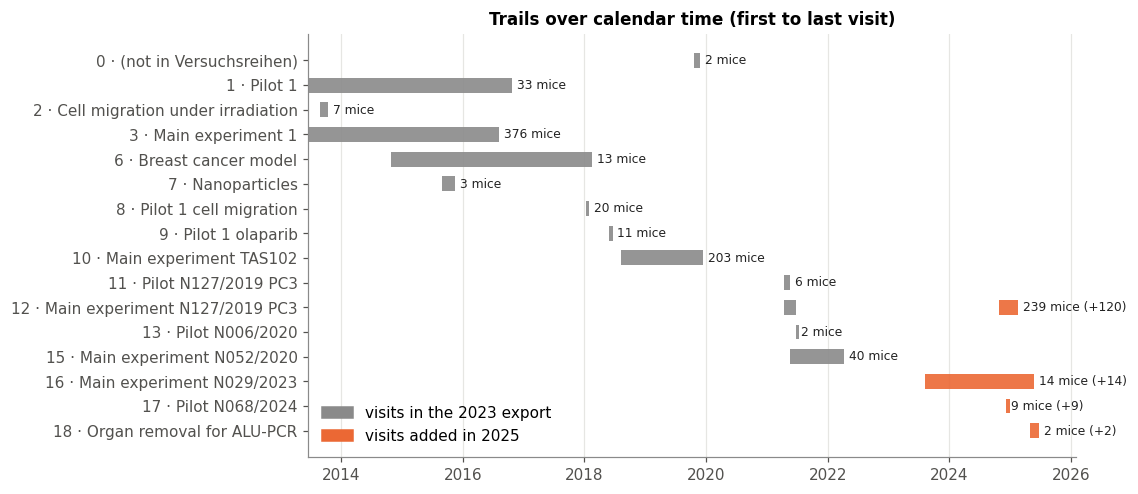

In [15]:
old_visit_ids = set(old["Visiten"]["IdVisite"])
N.visits["in_old"] = N.visits["visit_id"].isin(old_visit_ids)
old_mouse_ids = set(old["Versuchstiere"]["IdTier"])
N.mice["in_old"] = N.mice["id"].isin(old_mouse_ids)
growth = pd.DataFrame({
    "mice_old": O.mice.groupby("trail").size(), "mice_new": N.mice.groupby("trail").size(),
    "visits_old": O.visits.groupby("trail").size(), "visits_new": N.visits.groupby("trail").size(),
}).fillna(0).astype(int)
growth["mice_added"] = growth["mice_new"] - growth["mice_old"]
growth["visits_added"] = growth["visits_new"] - growth["visits_old"]
growth["new trail"] = ~growth.index.isin(O.vr.index) & growth.index.isin(N.vr.index)
growth.index = growth.index.astype(int)
display(growth[(growth["mice_added"] > 0) | (growth["visits_added"] > 0)])

known = N.visits.dropna(subset=["date", "trail"])
spans = known.groupby(["trail", "in_old"])["date"].agg(["min", "max"]).unstack("in_old")
order = sorted(known["trail"].unique().astype(int), reverse=True)
fig, ax = plt.subplots(figsize=(9, 5))
for y, t in enumerate(order):
    for in_old, color in [(True, MUTED), (False, NEW_COLOR)]:
        if (("min", in_old) in spans.columns) and pd.notna(spans.loc[t, ("min", in_old)]):
            start, end = mdates.date2num(spans.loc[t, ("min", in_old)]), mdates.date2num(spans.loc[t, ("max", in_old)])
            ax.barh(y, max(end - start, 20), left=start, height=0.6, color=color, alpha=0.9)
    ax.text(mdates.date2num(known.loc[known["trail"] == t, "date"].max()) + 30, y,
            f"{growth.loc[t, 'mice_new']} mice" + (f" (+{growth.loc[t, 'mice_added']})" if growth.loc[t, "mice_added"] else ""),
            va="center", fontsize=8, color=INK)
ax.set_yticks(range(len(order)), [f"{t} · {N.trail_name(t)}" for t in order])
ax.xaxis_date()
ax.grid(axis="y", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=MUTED, label="visits in the 2023 export"),
                   plt.Rectangle((0, 0), 1, 1, color=NEW_COLOR, label="visits added in 2025")], loc="lower left")
ax.set_title("Trails over calendar time (first to last visit)")
plt.show()

## B3. Protocols per trail
Radiotherapy concepts (`RTKonzepte`, from the fractions in `Bestrahlungen`) and chemotherapy drugs and
concepts (from `Chemotherapie`), with the number of mice. The schedule is fractions x dose per fraction of the
concept (the concepts also differ in beam energy, 200 vs 225 kV). The last columns show how much of each
trail uses the same RT schedule and ChT drugs as trail 3.

In [16]:
rt_concepts = N.tables["RTKonzepte"].set_index("IdRTKonzept")
rt = N.radio.merge(rt_concepts[["Einzeldosis", "Fraktionen"]], left_on="IdRTKonzept", right_index=True, how="left")
rt["schedule"] = rt["Fraktionen"].astype(str) + " x " + rt["Einzeldosis"].astype(str) + " Gy"
rt_per_mouse = rt.groupby(["trail", "id"]).agg(concept=("concept", "first"), schedule=("schedule", "first"),
                                                fractions=("IdBestrahlung", "size"), dose=("DosisIst", "sum"))
cht_per_mouse = N.chemo.groupby(["trail", "id"]).agg(drug=("drug", "first"), concept=("concept", "first"),
                                                      administrations=("IdChemo", "size"), dose=("ChTKonzIst", "median"),
                                                      route=("route", "first"))
rt3 = set(rt_per_mouse.loc[TRAIL, "schedule"])
cht3 = set(cht_per_mouse.loc[TRAIL, "drug"])
protocols = pd.DataFrame({
    "RT concepts (mice)": rt_per_mouse.groupby("trail")["concept"].agg(join_counts),
    "RT schedules (mice)": rt_per_mouse.groupby("trail")["schedule"].agg(join_counts),
    "RT fractions per mouse": rt_per_mouse.groupby("trail")["fractions"].agg(median_iqr),
    "RT total dose per mouse (Gy)": rt_per_mouse.groupby("trail")["dose"].agg(median_iqr),
    "ChT drugs (mice)": cht_per_mouse.groupby("trail")["drug"].agg(join_counts),
    "ChT concepts (mice)": cht_per_mouse.groupby("trail")["concept"].agg(join_counts),
    "ChT administrations per mouse": cht_per_mouse.groupby("trail")["administrations"].agg(median_iqr),
    "ChT routes": cht_per_mouse.groupby("trail")["route"].agg(join_unique),
    "% RT mice with a trail-3 RT schedule": rt_per_mouse.groupby("trail")["schedule"].agg(lambda s: round(100 * s.isin(rt3).mean())),
    "% ChT mice with a trail-3 drug": cht_per_mouse.groupby("trail")["drug"].agg(lambda s: round(100 * s.isin(cht3).mean())),
})
protocols.index = protocols.index.astype(int)
protocols.fillna("")

,RT concepts (mice),RT schedules (mice),RT fractions per mouse,RT total dose per mouse (Gy),ChT drugs (mice),ChT concepts (mice),ChT administrations per mouse,ChT routes,% RT mice with a trail-3 RT schedule,% ChT mice with a trail-3 drug
trail,,,,,,,,,,
0,d1-5 2.0 Gy 1,5 x 2 Gy 1,3 [3–3],9 [9–9],,,,,0.0,
1,"d1-5 10,0 Gy 8",5 x 10 Gy 8,5 [5–5],50 [48–50],"Cisplatin 19, Etoposid 6, Docetaxel 3","BC Standard alt 9, Doctaxel 20 mg/kg d1-8-15 3, Cisplatin 6mg/kg d1 2, Cispl...",3 [3–4],i.p.,100.0,79.0
2,"d1 10,0 Gy 6, d1 15,0 Gy 1","1 x 10 Gy 6, 1 x 15 Gy 1",1 [1–1],10 [10–10],,,,,0.0,
3,"d1-5 10,0 Gy 134",5 x 10 Gy 134,5 [5–5],50 [50–50],"Cisplatin 76, Docetaxel 40","Cisplatin 6mg/kg d1 76, Doctaxel 20 mg/kg d1-8-15 40",1 [1–3],i.p.,100.0,100.0
4,"d1 6 Gy - Femora 3, d1 6 Gy - Mamma 3","2 x 6 Gy 3, 1 x 6 Gy 3",2 [1–2],9 [6–12],,,,,0.0,
6,"Mamma02 d1 10,0 Gy 11, Mamma01 d1 3,0 Gy 1","1 x 10 Gy 11, 1 x 3 Gy 1",1 [1–1],10 [10–10],,,,,0.0,
7,"d1-5 10,0 Gy 3",5 x 10 Gy 3,5 [5–5],50 [50–50],,,,,100.0,
8,"d1-4 10.0 Gy 1, d1 10,0 Gy 1, d1-3 10.0 Gy 1, d1-5 10,0 Gy 1, d1-2 10.0 Gy 1","4 x 10 Gy 1, 1 x 10 Gy 1, 3 x 10 Gy 1, 5 x 10 Gy 1, 2 x 10 Gy 1",3 [2–4],30 [20–40],,,,,20.0,
9,d1 2.0 Gy 8,1 x 2 Gy 8,1 [1–1],2 [2–2],Olaparib 6,Olaparib 2h vor RT 6,1 [1–1],oral gavage,0.0,0.0


In [17]:
display(rt_concepts.loc[sorted(rt["IdRTKonzept"].unique()), ["RTKonzept", "Einzeldosis", "Enddosis", "Fraktionen", "FrakTag",
                                                            "FrakWo", "Qualitaet", "Bemerkung"]]
        .rename(columns={"Einzeldosis": "dose per fraction (Gy)", "Enddosis": "total dose (Gy)", "Fraktionen": "fractions",
                         "FrakTag": "fractions/day", "FrakWo": "fractions/week", "Qualitaet": "beam"}))
display(N.tables["ChTKonzepte"].set_index("IdChTKonzept").loc[sorted(N.chemo["IdChTKonzept"].unique()),
        ["NameChTKonzept", "IdChTMed1", "ChTKonz1", "ChTTage1", "IdChTMed2", "ChTKonz2", "ChTTage2", "Bemerkung"]]
        .rename(columns={"NameChTKonzept": "protocol", "ChTKonz1": "dose 1 (mg/kg)", "ChTTage1": "days 1",
                         "ChTKonz2": "dose 2 (mg/kg)", "ChTTage2": "days 2"}))

,RTKonzept,dose per fraction (Gy),total dose (Gy),fractions,fractions/day,fractions/week,beam,Bemerkung
IdRTKonzept,,,,,,,,
1,"d1-5 10,0 Gy",10,50,5,1,5,200 kV,Standard 5 x 10 Gy
2,"d1 10,0 Gy",10,10,1,1,1,200 kV,Standard 1 x 10 Gy
3,"d1 15,0 Gy",15,15,1,1,1,200 kV,Kooperation Zellmigration
4,d1 6 Gy - Mamma,6,6,1,1,1,200 kV,Kooperation Mammabestrahlung
5,d1 6 Gy - Femora,6,12,2,2,2,200 kV,Kooperation Mammabestrahlung
6,"Mamma01 d1 3,0 Gy",3,3,1,1,1,200 kV,Kooperation Brustkrebs
7,"Mamma02 d1 10,0 Gy",10,10,1,1,1,200 kV,Kooperation Brustkrebs
8,d1-4 10.0 Gy,10,40,4,1,4,200 kV,Standard 4 x 10 Gy
9,d1-3 10.0 Gy,10,30,3,1,3,200 kV,Standard 3 x 10 Gy


,protocol,IdChTMed1,dose 1 (mg/kg),days 1,IdChTMed2,dose 2 (mg/kg),days 2,Bemerkung
IdChTKonzept,,,,,,,,
1,BC Standard alt,1,6,1,2.0,12.0,3,None
2,Doctaxel 20 mg/kg d1-8-15,3,20,3,NaN,NaN,None,None
3,Cisplatin Dosis 1/3,1,2,1,NaN,NaN,None,None
4,Cisplatin Dosis 2/3,1,4,1,NaN,NaN,None,None
5,Cisplatin 6mg/kg d1,1,6,1,0.0,0.0,,
6,Etoposid Dosis 1/3,2,4,3,NaN,NaN,None,None
7,Etoposid Dosis 2/3,2,8,3,NaN,NaN,None,None
8,Etoposid Dosis 3/3,2,12,3,NaN,NaN,None,None
9,Cisplatin + Pause + Etoposid,1,6,1,2.0,12.0,3,"Cisplatin d1, Etoposid d3-5"


## B4. Roles 12–14 (new in 2025)

In [18]:
special_roles = [r for r in (12, 13, 14) if r in set(N.mice["role"])]
special = N.mice[N.mice["role"].isin(special_roles)]
display(pd.DataFrame({r: N.role_name[r] for r in special_roles}, index=["meaning"]).T)
display(pd.crosstab(special["trail"], special["role_abbr"].rename("role"), margins=True, margins_name="Total"))
MOUSE_TABLES = ["Visiten", "Bestrahlungen", "Chemotherapie", "Operationen", "Narkosen", "Tumor", "Gewebe", "Blut",
                "Knochenmark", "Kryo", "Paraffin", "PCR"]
measured = pd.DataFrame({t: special.groupby("role_abbr")["id"].agg(lambda ids: int(new[t]["IdTier"].isin(ids).sum()))
                         for t in MOUSE_TABLES})
measured.insert(0, "mice", special.groupby("role_abbr").size())
say("Rows per table for the mice of these roles:")
display(measured)
special_visits = N.visits[N.visits["id"].isin(special["id"])]
display(special_visits.groupby("id").agg(trail=("trail", "first"), role=("role", "first"), visits=("weight", "size"),
                                         first=("date", "min"), last=("date", "max"), weight=("weight", "median")))

,meaning
12,OE: organ removal
13,MP: injection of macrophages
14,NP: injection of nanoparticles


role,MP,NP,OE,Total
trail,,,,
16,3,1,0,4
18,0,0,2,2
Total,3,1,2,6


Rows per table for the mice of these roles:

,mice,Visiten,Bestrahlungen,Chemotherapie,Operationen,Narkosen,Tumor,Gewebe,Blut,Knochenmark,Kryo,Paraffin,PCR
role_abbr,,,,,,,,,,,,,
MP,3,97,0,0,0,0,3,0,0,0,0,0,0
NP,1,32,0,0,0,0,1,0,0,0,0,0,0
OE,2,116,0,0,0,0,0,16,2,2,6,8,0


,trail,role,visits,first,last,weight
id,,,,,,
985,16.0,13.0,32,2025-04-29,2025-05-24,18.10
986,16.0,13.0,31,2025-04-29,2025-05-24,18.90
987,16.0,14.0,32,2025-04-29,2025-05-25,17.90
988,16.0,13.0,34,2025-04-29,2025-05-25,20.00
989,18.0,12.0,58,2025-04-29,2025-06-24,20.05
990,18.0,12.0,58,2025-04-29,2025-06-24,23.15


In [19]:
n_new_trails = int(growth["new trail"].sum())
t12 = growth.loc[12]
comparable = protocols[(protocols["% RT mice with a trail-3 RT schedule"].fillna(0) >= 50)].index.tolist()
cht_shared = protocols[(protocols["% ChT mice with a trail-3 drug"].fillna(0) >= 50)].index.tolist()
big_trails = [t for t in trails_new.index[trails_new["mice"] > 100] if t != TRAIL]
say(f"""**What this tells us (Part B).**
- The new export has {len(N.vr)} trails ({n_new_trails} new: {", ".join(str(t) for t in growth.index[growth["new trail"]])}).
  Most of the growth is trail 12, which went from {t12['mice_old']} to {t12['mice_new']} mice and from
  {t12['visits_old']:,} to {t12['visits_new']:,} visits; the new trails are small
  ({", ".join(f"trail {t}: {growth.loc[t, 'mice_new']} mice" for t in growth.index[growth["new trail"]])}).
- Trail 3 remains the largest trail ({trails_new.loc[TRAIL, 'mice']} mice); the only other trails with more than 100 mice
  are {", ".join(f"{t} ({trails_new.loc[t, 'mice']})" for t in big_trails)}.
- Trails in which at least half of the irradiated mice got trail 3's RT schedule ({", ".join(sorted(rt3))}):
  {", ".join(map(str, comparable))}. Trails in which at least half of the ChT mice got a trail-3 drug
  ({", ".join(sorted(cht3))}): {", ".join(map(str, cht_shared))}. The other trails ran different protocols
  (e.g. fractionated 2–3 Gy schedules, TAS102/capecitabine) and are different experiments.
- Roles 12–14 cover {len(special)} mice in trail(s) {join_unique(special['trail'].astype(int))} with
  {len(special_visits)} visits ({100 * len(special_visits) / len(N.visits):.1f}% of all visits); their weights were recorded
  but they got no RT/ChT, and the organ-removal mice have necropsy samples only.
""")

**What this tells us (Part B).**
- The new export has 18 trails (3 new: 16, 17, 18).
  Most of the growth is trail 12, which went from 119 to 239 mice and from
  4,705 to 10,062 visits; the new trails are small
  (trail 16: 14 mice, trail 17: 9 mice, trail 18: 2 mice).
- Trail 3 remains the largest trail (376 mice); the only other trails with more than 100 mice
  are 10 (203), 12 (239).
- Trails in which at least half of the irradiated mice got trail 3's RT schedule (5 x 10 Gy):
  1, 3, 7, 11, 12. Trails in which at least half of the ChT mice got a trail-3 drug
  (Cisplatin, Docetaxel): 1, 3, 11, 12, 15. The other trails ran different protocols
  (e.g. fractionated 2–3 Gy schedules, TAS102/capecitabine) and are different experiments.
- Roles 12–14 cover 6 mice in trail(s) 16, 18 with
  245 visits (0.9% of all visits); their weights were recorded
  but they got no RT/ChT, and the organ-removal mice have necropsy samples only.


# Part C: usability per trail for weight forecasting

## C1. Cohort flow per trail
Replays `michael.load_dataset` step by step (as v1 C1), for all trails at once. Each column is the number of
mice left after that filter. "lost to the trail-start filter" counts mice that would have had enough weights
if the records before the trail start or birth were not dropped. The final column is checked against
`michael.load_dataset`.

In [20]:
def cohort_flow(path, tables, roles, untreated=michael.UNTREATED, cfg=None):
    """Mice per trail after each filter of michael.load_dataset, and the loader's result for the same settings."""
    cfg = cfg or config(sorted(tables["Versuchsreihen"]["IdVersuchsreihe"]), roles)
    columns = preprocessing.MOUSE_COLUMNS | {"Geburtsdatum": "birth date", "Sterbedatum": "death date"}
    m_all = tables["Versuchstiere"][list(columns)].rename(columns=columns)
    starts = tables["Versuchsreihen"][["IdVersuchsreihe", "VersuchStart"]].rename(
        columns={"IdVersuchsreihe": "trail", "VersuchStart": "trail start"})
    m = m_all.merge(starts, on="trail", how="left")
    for column in ("birth date", "death date", "trail start"):
        m[column] = pd.to_datetime(m[column], errors="coerce")
    m_dead = m[m["trail"].isin(starts["trail"]) & m["role"].isin(roles) & m["death date"].notna()]
    events = michael._build_events(tables, m_dead).merge(m_dead[["id", "trail", "role", "birth date", "trail start"]], on="id")
    events["days_since"] = (events["date"] - events["trail start"]).dt.days
    dated = events[(events["date"] >= events["birth date"]) & (events["days_since"] >= 0)]
    dated = dated.assign(weight=dated["weight"].round(2)).sort_values(["id", "days_since"], kind="stable")
    per = dated.groupby("id").agg(events=("event", lambda e: tuple(e.unique())), n=("weight", "count"),
                                  min_weight=("weight", "min"), max_weight=("weight", "max")).reindex(m["id"])
    per.index = m.index
    n_undated = events.groupby("id")["weight"].count().reindex(m["id"]).fillna(0).to_numpy()
    steps = {
        "in Versuchsreihen": m["trail"].isin(starts["trail"]),
        f"role in {list(roles) if len(roles) < 6 else 'all'}": m["role"].isin(roles),
        "death date known": m["death date"].notna(),
        "treated (RT/ChT/OP recorded)": per["events"].map(lambda e: isinstance(e, tuple) and e not in untreated),
        f"≥ {cfg.min_length} weights after trail start": per["n"] >= cfg.min_length,
        "all weights > 0 g": per["min_weight"] > 0,
        f"all weights ≤ {cfg.max_weight:g} g": per["max_weight"] <= cfg.max_weight,
    }
    flow = pd.DataFrame({"all mice": m.groupby("trail").size()})
    mask = pd.Series(True, index=m.index)
    for label, step in steps.items():
        mask &= step.fillna(False).astype(bool)
        flow[label] = mask.groupby(m["trail"]).sum()
    lost_start = (per["n"].fillna(0) < cfg.min_length) & (n_undated >= cfg.min_length) & m.index.isin(m_dead.index)
    flow["lost to the trail-start filter"] = lost_start.groupby(m["trail"]).sum()
    flow.index = flow.index.astype(int)
    with mock.patch.object(michael, "UNTREATED", untreated):
        loaded = michael.load_dataset(path, cfg)
    kept = set(m.loc[mask, "id"])
    assert kept == set(loaded["item_id"]), "replay does not match michael.load_dataset"
    return flow, loaded


flow13, D13 = cohort_flow(NEW_PATH, new, COHORT_ROLES)
say(f"**Roles RT/RChT/ChT** — kept: {D13['item_id'].nunique()} mice, {len(D13):,} rows "
    f"(old export: {df_all_old['item_id'].nunique()} mice, {len(df_all_old):,} rows)")
flow13

**Roles RT/RChT/ChT** — kept: 519 mice, 16,376 rows (old export: 434 mice, 12,397 rows)

,all mice,in Versuchsreihen,"role in [1, 2, 3]",death date known,treated (RT/ChT/OP recorded),≥ 5 weights after trail start,all weights > 0 g,all weights ≤ 100 g,lost to the trail-start filter
trail,,,,,,,,,
0,2,0,0,0,0,0,0,0,0
1,33,33,31,29,29,29,26,26,0
2,7,7,7,0,0,0,0,0,0
3,376,376,188,188,188,188,187,186,0
4,6,6,6,0,0,0,0,0,0
5,2,2,0,0,0,0,0,0,0
6,13,13,13,13,13,0,0,0,0
7,3,3,3,3,3,3,3,3,0
8,20,20,5,5,5,5,5,5,0


Mice kept per trail and role:

In [21]:
named = lambda d: pd.crosstab(d.drop_duplicates("item_id")["trail"], d.drop_duplicates("item_id")["role"].map(N.role_abbr).rename("role"),
                              margins=True, margins_name="Total")
named(D13)

role,ChT,RChT,RT,Total
trail,,,,
1,18,7,1,26
3,53,60,73,186
7,0,0,3,3
8,0,0,5,5
10,44,71,38,153
11,1,1,4,6
12,36,39,39,114
15,0,0,17,17
16,9,0,0,9


## C2. Widening the role filter
The same flow with all roles. Controls and other untreated mice are then removed by the *treated* filter
(Michael's loader drops mice without RT/ChT/OP), so a second run switches that filter off
(`michael.UNTREATED` patched to an empty list, inside this notebook only) to see what the untreated mice
could add as context.

In [22]:
all_roles = sorted(set(N.mice["role"]))
flow_all, D_allroles = cohort_flow(NEW_PATH, new, all_roles)
flow_ctx, D_ctx = cohort_flow(NEW_PATH, new, all_roles, untreated=[])
say(f"All roles: {D_allroles['item_id'].nunique()} mice kept with the treatment filter, "
    f"{D_ctx['item_id'].nunique()} mice and {len(D_ctx):,} rows without it.")
display(flow_all)


def series_summary(d):
    pm = d.sort_values(["item_id", "timestamp"]).groupby("item_id").agg(
        trail=("trail", "first"), role=("role", "first"), n=("target", "size"), baseline=("target", "first"),
        treated=("intervention", "max"), first=("timestamp", "min"), last=("timestamp", "max"))
    pm["median_gap"] = d.sort_values(["item_id", "timestamp"]).groupby("item_id")["timestamp"].apply(
        lambda s: s.diff().dt.days.median())
    return pm


pm_ctx = series_summary(D_ctx)
by_role = pm_ctx.groupby("role").agg(
    mice=("n", "size"), rows=("n", "sum"), with_treatment=("treated", "sum"),
    series_length=("n", median_iqr), median_gap_days=("median_gap", median_iqr),
    baseline_weight_g=("baseline", lambda x: median_iqr(x, 1)), trails=("trail", join_counts))
by_role.index = [f"{r} {N.role_abbr.get(r, '?')}" for r in by_role.index]
by_role

All roles: 740 mice kept with the treatment filter, 888 mice and 26,974 rows without it.

,all mice,in Versuchsreihen,role in all,death date known,treated (RT/ChT/OP recorded),≥ 5 weights after trail start,all weights > 0 g,all weights ≤ 100 g,lost to the trail-start filter
trail,,,,,,,,,
0,2,0,0,0,0,0,0,0,0
1,33,33,33,31,31,31,28,28,0
2,7,7,7,0,0,0,0,0,0
3,376,376,376,376,310,290,289,288,0
4,6,6,6,0,0,0,0,0,0
5,2,2,2,2,0,0,0,0,0
6,13,13,13,13,13,0,0,0,0
7,3,3,3,3,3,3,3,3,0
8,20,20,20,20,20,20,20,20,0


,mice,rows,with_treatment,series_length,median_gap_days,baseline_weight_g,trails
0 –,5,150,0,30 [30–30],1 [1–1],31.2 [30.0–32.3],10 5
1 RT,180,5761,180,31 [16–41],1 [1–2],23.5 [21.4–26.3],"3 73, 12 39, 10 38, 15 17, 8 5, 11 4, 7 3, 1 1"
2 RChT,178,5812,178,34 [16–43],1 [1–2],23.6 [21.1–27.2],"10 71, 3 60, 12 39, 1 7, 11 1"
3 ChT,163,4838,161,27 [16–40],1 [1–3],24.2 [21.1–27.1],"3 53, 10 46, 12 36, 1 18, 16 9, 11 1"
4 K,86,1914,0,18 [8–32],1 [1–6],22.8 [20.9–25.4],"3 40, 12 40, 8 6"
5 E,160,3908,2,22 [14–36],1 [1–3],23.6 [21.5–27.1],"3 73, 12 39, 10 29, 15 13, 8 6"
7 B,6,208,0,22 [22–45],2 [1–6],25.8 [24.4–26.6],"8 3, 1 2, 3 1"
8 KT,42,1869,0,46 [13–74],1 [1–7],25.5 [22.7–28.7],"3 33, 15 7, 10 1, 12 1"
9 OP,62,2294,62,37 [31–42],1 [1–1],21.2 [20.3–23.2],"12 44, 3 18"
12 OE,2,114,0,57 [57–57],1 [1–1],11.5 [11.3–11.7],18 2


## C3. Series characteristics per trail
For the roles RT/RChT/ChT through `michael.load_dataset` (`D13`), all trails. Gaps are days between
consecutive rows of a mouse; loss is the lowest weight relative to the first one.

In [23]:
def per_mouse_table(d):
    s = d.sort_values(["item_id", "timestamp"])
    pm = s.groupby("item_id").agg(trail=("trail", "first"), role=("role", "first"), n=("target", "size"),
                                  first=("timestamp", "min"), last=("timestamp", "max"), baseline=("target", "first"),
                                  min_weight=("target", "min"), intervention_rows=("intervention", "sum"))
    pm["nadir_pct"] = 100 * pm["min_weight"] / pm["baseline"]
    first_treat = s[s["intervention"] > 0].groupby("item_id")["timestamp"].min()
    pm["first_treatment"] = first_treat
    pm["measurements_before_treatment"] = s.assign(before=s["timestamp"] < s["item_id"].map(first_treat)).groupby("item_id")["before"].sum()
    return pm


def gaps_table(d):
    s = d.sort_values(["item_id", "timestamp"]).copy()
    s["gap"] = s.groupby("item_id")["timestamp"].diff().dt.days
    s["delta"] = s.groupby("item_id")["target"].diff()
    return s


pm13 = per_mouse_table(D13)
g13 = gaps_table(D13)
trail_counts = pm13["trail"].value_counts()
kept_trails = sorted(trail_counts[trail_counts >= MIN_MICE].index.astype(int))
characteristics = pd.DataFrame({
    "mice": pm13.groupby("trail").size(),
    "rows": D13.groupby("trail").size(),
    "series length": pm13.groupby("trail")["n"].agg(median_iqr),
    "median gap (days)": g13.groupby("trail")["gap"].median(),
    "% gaps of 1 day": g13.groupby("trail")["gap"].agg(lambda x: round(100 * (x == 1).mean())),
    "% gaps of 7 days": g13.groupby("trail")["gap"].agg(lambda x: round(100 * (x == 7).mean())),
    "% gaps > 7 days": g13.groupby("trail")["gap"].agg(lambda x: round(100 * (x > 7).mean())),
    "% rows on Mondays": D13.groupby("trail")["timestamp"].agg(lambda x: round(100 * (x.dt.dayofweek == 0).mean())),
    "time of day (h)": D13.groupby("trail")["time_of_day"].agg(lambda x: median_iqr(x, 1)),
    "% rows without time": D13.groupby("trail")["time_of_day"].agg(lambda x: round(100 * x.isna().mean())),
    "baseline weight (g)": pm13.groupby("trail")["baseline"].agg(lambda x: median_iqr(x, 1)),
    "step change SD (g)": g13.groupby("trail")["delta"].std().round(2),
    "% mice with ≥ 10% loss": pm13.groupby("trail")["nadir_pct"].agg(lambda x: round(100 * (x <= 90).mean())),
    "% mice with ≥ 20% loss": pm13.groupby("trail")["nadir_pct"].agg(lambda x: round(100 * (x <= 80).mean())),
    "% rows with treatment": D13.groupby("trail")["intervention"].agg(lambda x: round(100 * x.mean())),
    "weights before first treatment": pm13.groupby("trail")["measurements_before_treatment"].agg(median_iqr),
})
characteristics.index = characteristics.index.astype(int)
characteristics

,mice,rows,series length,median gap (days),% gaps of 1 day,% gaps of 7 days,% gaps > 7 days,% rows on Mondays,time of day (h),% rows without time,baseline weight (g),step change SD (g),% mice with ≥ 10% loss,% mice with ≥ 20% loss,% rows with treatment,weights before first treatment
trail,,,,,,,,,,,,,,,,
1,26,1047,28 [8–76],7.0,15,56,4,67,10.9 [9.6–13.3],0,25.1 [24.2–27.1],0.90,54,35,8,0 [0–5]
3,186,3049,15 [11–16],2.0,44,24,1,45,12.2 [10.1–16.1],0,25.6 [22.8–27.8],1.02,57,22,26,7 [3–8]
7,3,39,13 [13–13],4.5,31,0,23,15,9.6 [7.5–15.5],0,21.3 [21.2–21.8],0.70,0,0,38,3 [3–3]
8,5,110,22 [22–22],1.0,95,0,0,18,9.5 [8.4–10.4],0,24.1 [23.7–25.4],0.47,40,0,14,14 [14–14]
10,153,5808,37 [27–48],1.0,93,0,0,16,11.7 [9.8–13.2],0,24.4 [21.8–28.9],0.43,21,3,20,14 [12–14]
11,6,181,29 [29–33],1.0,95,0,0,14,8.8 [8.2–10.4],0,21.1 [20.2–23.1],0.62,50,17,9,22 [18–27]
12,114,4900,40 [40–45],1.0,98,0,0,14,10.0 [8.5–11.6],0,20.8 [19.3–21.7],0.52,13,3,10,32 [31–36]
15,17,900,43 [17–81],1.0,98,0,0,14,6.9 [6.8–7.0],0,26.8 [25.1–29.9],0.73,41,12,16,0 [0–1]
16,9,342,47 [5–62],1.0,97,0,0,14,9.6 [8.1–11.2],0,23.0 [20.9–24.3],0.36,0,0,3,46 [4–61]


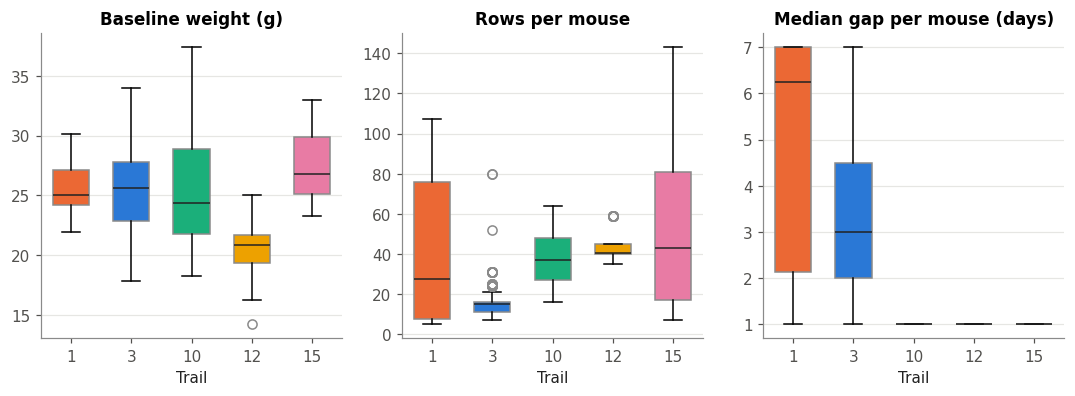

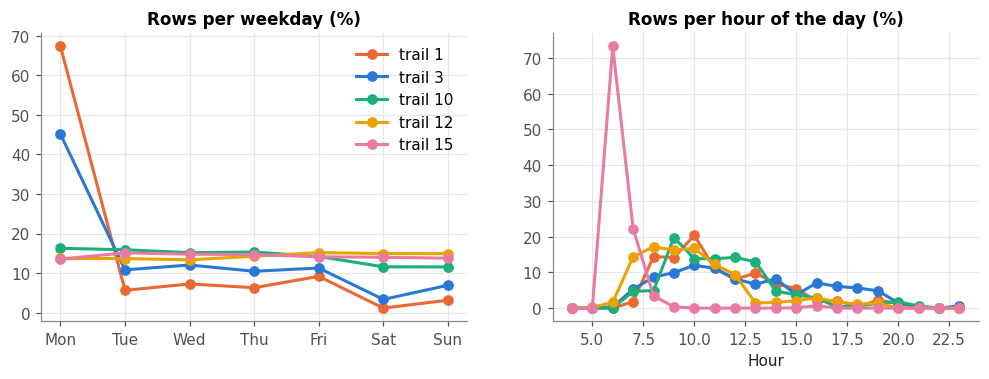

In [24]:
colors = trail_colors(kept_trails)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (data, label) in zip(axes, [(pm13["baseline"], "Baseline weight (g)"), (pm13["n"], "Rows per mouse"),
                                     (g13.groupby("item_id")["gap"].median(), "Median gap per mouse (days)")]):
    values = [data[pm13["trail"] == t].dropna() for t in kept_trails]
    box = ax.boxplot(values, patch_artist=True, widths=0.6, medianprops={"color": INK}, flierprops={"markeredgecolor": MUTED})
    for patch, t in zip(box["boxes"], kept_trails):
        patch.set_facecolor(colors[t])
        patch.set_edgecolor(MUTED)
    ax.set_xticks(range(1, len(kept_trails) + 1), kept_trails)
    ax.set_xlabel("Trail")
    ax.set_title(label)
    ax.grid(axis="x", visible=False)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
weekday_share = pd.crosstab(D13["trail"], D13["timestamp"].dt.dayofweek, normalize="index").mul(100).loc[kept_trails]
hour_share = pd.crosstab(D13["trail"], np.floor(D13["time_of_day"]), normalize="index").mul(100).loc[kept_trails]
for t in kept_trails:
    axes[0].plot(weekday_share.columns, weekday_share.loc[t], marker="o", color=colors[t], label=f"trail {t}")
    axes[1].plot(hour_share.columns, hour_share.loc[t], marker="o", color=colors[t], label=f"trail {t}")
axes[0].set_xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[0].set_title("Rows per weekday (%)")
axes[1].set_title("Rows per hour of the day (%)")
axes[1].set_xlabel("Hour")
axes[0].legend()
plt.show()

## C4. Shift against trail 3
Population, era and protocol of the trails with at least `MIN_MICE` kept mice, and the weight course
aligned at the first treatment (median over mice in 3-day bins, as v1 C4).

,mice,strain,% male,cell lines,years,roles,RT concepts,ChT drugs,days first row → first treatment
trail,,,,,,,,,
1,26,"SCID 23, PFP/RAG2 3",81,"PC-3 RGB 3, OH-1 RGB 3, H69 RGB 2",2013–2013,"ChT 18, RChT 7, RT 1","d1-5 10,0 Gy 8","Cisplatin 16, Etoposid 6, Docetaxel 3",0 [0–21]
3,186,"SCID 128, PFP/RAG2 58",66,"OH-1 RGB 81, LNCaP RGB 58, H69 RGB 47",2013–2016,"RT 73, RChT 60, ChT 53","d1-5 10,0 Gy 133","Cisplatin 74, Docetaxel 40",28 [21–49]
10,153,PFP/RAG2 153,43,"SW48 55, HT29 49, HCT116 49",2018–2019,"RChT 71, ChT 44, RT 38","d1-10 3,0 Gy 64, d1-5 2.0 Gy 37, d1 2.0 Gy 4, d1 3.0 Gy 4","TAS102 67, Capecitabine 48",14 [14–16]
12,114,SCID 114,100,"PC-3DR RGB + Luziferase 60, PC-3 RGB + Luziferase 54",2021–2024,"RChT 39, RT 39, ChT 36","d1-5 10,0 Gy 225 kV 69, d1-5 10,0 Gy 9",Docetaxel 75,32 [31–36]
15,17,NMRI-Foxn1nu 17,0,NCH644OBC 17,2021–2022,RT 17,"d1-10 2.0 Gy 10, d1-6 6x2,0 Gy 7",NaN,0 [0–1]


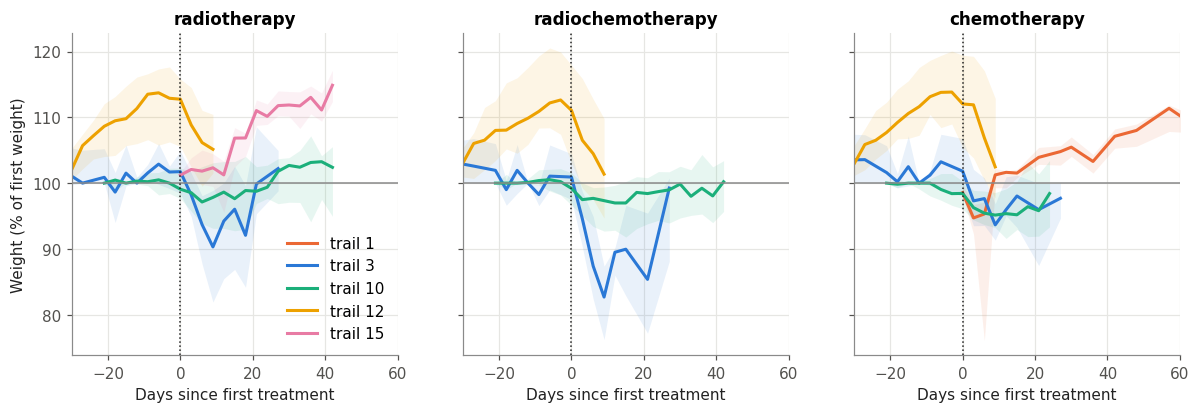

In [25]:
mice_k = N.mice.set_index("id").loc[pm13.index]
shift = pd.DataFrame({
    "mice": pm13.groupby("trail").size(),
    "strain": mice_k.groupby("trail")["strain"].agg(join_counts),
    "% male": mice_k.groupby("trail")["sex"].agg(lambda s: round(100 * (s == "male").mean())),
    "cell lines": mice_k.groupby("trail")["cell_line"].agg(join_counts),
    "years": pm13.groupby("trail")["first"].agg(lambda x: f"{x.dt.year.min()}–{x.dt.year.max()}"),
    "roles": pm13.groupby("trail")["role"].agg(lambda r: join_counts(r.map(N.role_abbr))),
    "RT concepts": rt_per_mouse.reset_index().query("id in @pm13.index").groupby("trail")["concept"].agg(join_counts),
    "ChT drugs": cht_per_mouse.reset_index().query("id in @pm13.index").groupby("trail")["drug"].agg(join_counts),
    "days first row → first treatment": (pm13["first_treatment"] - pm13["first"]).dt.days.groupby(pm13["trail"]).agg(median_iqr),
}).loc[kept_trails]
display(shift)

traj = D13.join(pm13[["first_treatment", "baseline", "last"]], on="item_id")
traj["day_rel_treatment"] = (traj["timestamp"] - traj["first_treatment"]).dt.days
traj["rel_weight"] = 100 * traj["target"] / traj["baseline"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, role in zip(axes, COHORT_ROLES):
    for t in kept_trails:
        q = median_line(traj[(traj["trail"] == t) & (traj["role"] == role)], "day_rel_treatment", "rel_weight")
        if len(q):
            ax.fill_between(q.index, q["q1"], q["q3"], color=colors[t], alpha=0.1, linewidth=0)
            ax.plot(q.index, q["med"], color=colors[t], label=f"trail {t}")
    ax.axhline(100, color=MUTED, linewidth=1)
    ax.axvline(0, color=INK, linestyle=":", linewidth=1)
    ax.set_xlim(-30, 60)
    ax.set_title(N.role_name[role].split(":")[1].strip())
    ax.set_xlabel("Days since first treatment")
axes[0].set_ylabel("Weight (% of first weight)")
axes[0].legend(handles=[plt.Line2D([], [], color=colors[t], label=f"trail {t}") for t in kept_trails])
plt.show()

Time on study (tumour injection to death) per trail, RT/RChT/ChT mice of the kept series (v1's
Kaplan–Meier plot, by trail instead of role). As in v1, almost all deaths are planned, so the curves show
the follow-up design.

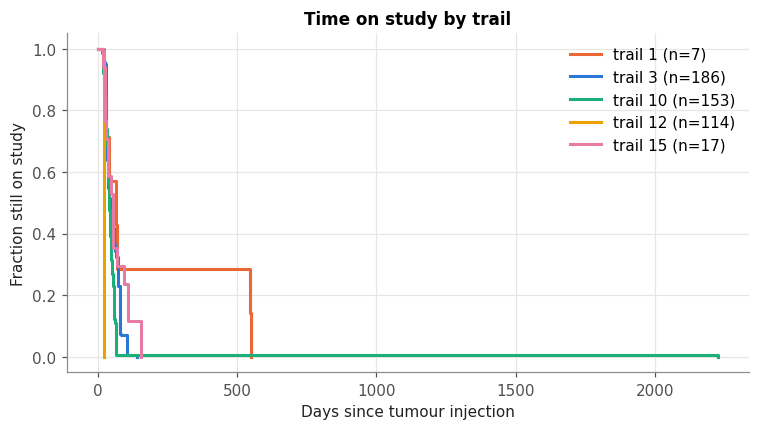

In [26]:
fig, ax = plt.subplots(figsize=(8, 4))
days_on_study = (mice_k["death"] - mice_k["injection"]).dt.days
for t in kept_trails:
    x = days_on_study[mice_k["trail"] == t].dropna()
    x = x[x >= 0]
    if len(x):
        sf = SurvfuncRight(x.to_numpy(float), np.ones(len(x)))
        ax.step(np.r_[0, sf.surv_times], np.r_[1, sf.surv_prob], where="post", color=colors[t], label=f"trail {t} (n={len(x)})")
ax.set_xlabel("Days since tumour injection")
ax.set_ylabel("Fraction still on study")
ax.set_title("Time on study by trail")
ax.legend()
plt.show()

## C5. Trail 12: old half vs new half
Trail-12 mice that are already in the 2023 export against those added since.

In [27]:
m12 = N.mice[N.mice["trail"] == 12].copy()
m12["half"] = np.where(m12["in_old"], "old (in 2023 export)", "new (added 2025)")
first_visit = N.visits.dropna(subset=["date"]).groupby("id")["date"].agg(["min", "max"])
m12 = m12.join(first_visit, on="id")
halves = m12.groupby("half").agg(
    mice=("id", "size"), first_visit=("min", "min"), last_visit=("max", "max"),
    cohorts=("cohort", join_counts), cell_lines=("cell_line", join_counts), strains=("strain", join_counts),
    roles=("role_abbr", join_counts), male=("sex", lambda s: int((s == "male").sum())),
)
half_of = m12.set_index("id")["half"]
rt12 = rt_per_mouse.loc[12].reset_index()
cht12 = cht_per_mouse.loc[12].reset_index()
halves["RT concepts"] = rt12.groupby(rt12["id"].map(half_of))["concept"].agg(join_counts)
halves["ChT drugs"] = cht12.groupby(cht12["id"].map(half_of))["drug"].agg(join_counts)
pm12 = pm13[pm13["trail"] == 12].assign(half=lambda x: x.index.map(half_of))
halves["kept series (RT/RChT/ChT)"] = pm12.groupby("half").size()
halves["series length"] = pm12.groupby("half")["n"].agg(median_iqr)
halves["baseline weight (g)"] = pm12.groupby("half")["baseline"].agg(lambda x: median_iqr(x, 1))
halves["lowest weight (% of first)"] = pm12.groupby("half")["nadir_pct"].agg(lambda x: median_iqr(x, 1))
g12 = g13[g13["trail"] == 12].assign(half=lambda x: x["item_id"].map(half_of))
halves["median gap (days)"] = g12.groupby("half")["gap"].median()
halves.T

half,new (added 2025),old (in 2023 export)
mice,120,119
first_visit,2024-10-24 00:00:00,2021-04-15 00:00:00
last_visit,2025-02-16 00:00:00,2021-06-25 00:00:00
cohorts,PC-3DR RGB + Luziferase Hauptversuch 120,PC-3 RGB + Luziferase Hauptversuch 119
cell_lines,PC-3DR RGB + Luziferase 120,PC-3 RGB + Luziferase 119
strains,SCID 120,SCID 119
roles,"K 20, ChT 20, RChT 20, OP 20, RT 20, E 19, KT 1","OP 24, K 20, E 20, RChT 20, RT 19, ChT 16"
male,120,119
RT concepts,"d1-5 10,0 Gy 225 kV 40","d1-5 10,0 Gy 225 kV 29, d1-5 10,0 Gy 10"
ChT drugs,Docetaxel 40,Docetaxel 36


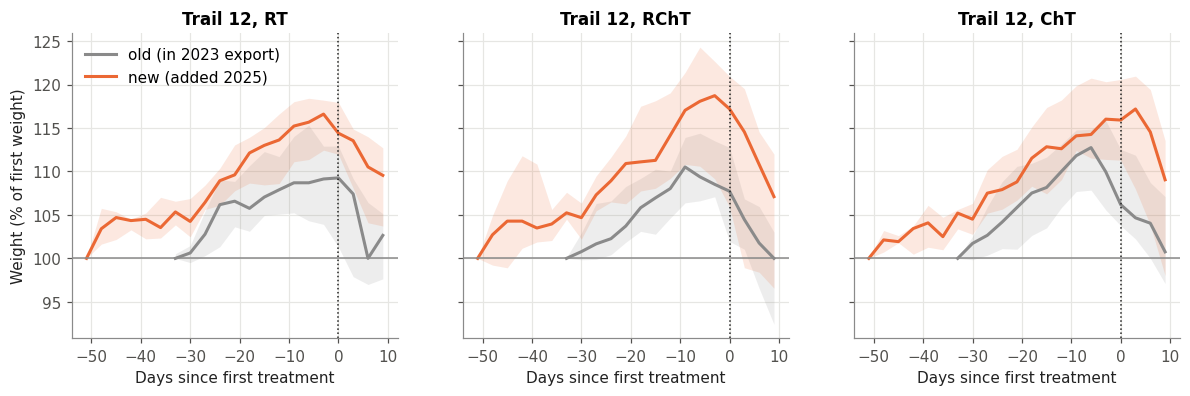

In [28]:
traj12 = traj[traj["trail"] == 12].assign(half=lambda x: x["item_id"].map(half_of))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, role in zip(axes, COHORT_ROLES):
    for half, color in [("old (in 2023 export)", MUTED), ("new (added 2025)", NEW_COLOR)]:
        q = median_line(traj12[(traj12["role"] == role) & (traj12["half"] == half)], "day_rel_treatment", "rel_weight", min_n=5)
        if len(q):
            ax.fill_between(q.index, q["q1"], q["q3"], color=color, alpha=0.15, linewidth=0)
            ax.plot(q.index, q["med"], color=color, label=half)
    ax.axhline(100, color=MUTED, linewidth=1)
    ax.axvline(0, color=INK, linestyle=":", linewidth=1)
    ax.set_title(f"Trail 12, {N.role_abbr[role]}")
    ax.set_xlabel("Days since first treatment")
axes[0].set_ylabel("Weight (% of first weight)")
axes[0].legend()
plt.show()

## C6. Naive last-value error per trail
The error of "next weight = last weight" on the rolling one-step-ahead origins (v1 C7), a yardstick for how
hard each trail is. *Overall* is the mean of the three role MAEs, as in the results tables. The rolling
machinery is run once on trail 3 and must match v1 (0.695 g); per trail the same numbers are computed
directly (the last-value forecast of origin *k* is weight *k − 1*).

In [29]:
last_value = {"Last value": lambda c, t: c.sort_values(["item_id", "timestamp"]).groupby("item_id", as_index=False)["target"]
              .last().rename(columns={"target": "prediction"})}
naive3 = rolling_metrics(rolling_predictions(df3_new, last_value, min_context=MIN_CONTEXT))
naive3_overall = float(naive3.xs("Overall", level="role")["MAE"].iloc[0])
print(f"Trail 3 via rolling_predictions: overall MAE {naive3_overall:.3f} g")
assert round(naive3_overall, 3) == 0.695


def naive_errors(d):
    """Absolute error of the last-value forecast for every rolling origin (step ≥ MIN_CONTEXT)."""
    s = d.sort_values(["item_id", "timestamp"]).copy()
    s["step"] = s.groupby("item_id").cumcount()
    s["ae"] = (s["target"] - s.groupby("item_id")["target"].shift()).abs()
    return s[s["step"] >= MIN_CONTEXT]


def naive_table(errors, by="trail"):
    per_role = errors.groupby([by, "role"])["ae"].mean().unstack("role")
    out = pd.DataFrame({"mice": errors.groupby(by)["item_id"].nunique(), "origins": errors.groupby(by).size()})
    for r in COHORT_ROLES:
        out[f"MAE {N.role_abbr[r]}"] = per_role.get(r)
    out["MAE overall (mean of roles)"] = per_role.reindex(columns=COHORT_ROLES).mean(axis=1, skipna=False)
    out["MAE all origins"] = errors.groupby(by)["ae"].mean()
    return out.round(3)


e13 = naive_errors(D13)
check3 = naive_table(e13[e13["trail"] == TRAIL]).loc[TRAIL, "MAE overall (mean of roles)"]
assert abs(check3 - naive3_overall) < 1e-3, (check3, naive3_overall)
naive_per_trail = naive_table(e13)
naive_per_trail.index = naive_per_trail.index.astype(int)
naive_per_trail

Trail 3 via rolling_predictions: overall MAE 0.695 g


,mice,origins,MAE RT,MAE RChT,MAE ChT,MAE overall (mean of roles),MAE all origins
trail,,,,,,,
1,26,995,0.996,0.536,0.561,0.697,0.564
3,186,2677,0.541,0.844,0.701,0.695,0.662
7,3,33,0.412,NaN,NaN,NaN,0.412
8,5,100,0.363,NaN,NaN,NaN,0.363
10,153,5502,0.147,0.172,0.175,0.165,0.166
11,6,169,0.450,0.484,0.500,0.478,0.466
12,114,4672,0.343,0.372,0.376,0.363,0.363
15,17,866,0.509,NaN,NaN,NaN,0.509
16,9,324,NaN,NaN,0.276,NaN,0.276


In [30]:
mae = naive_per_trail["MAE all origins"]
step_cols = list(flow13.columns[1:-1])
losses = pd.Series({b: int((flow13[a] - flow13[b]).sum()) for a, b in zip(["all mice"] + step_cols[:-1], step_cols)})
top_losses = losses.sort_values(ascending=False).head(3)
extra = pm_ctx.loc[~pm_ctx.index.isin(D13["item_id"])]
extra_controls = int(extra["role"].isin([4, 5]).sum())
bigger = [t for t in kept_trails if t != TRAIL]
same_strain = [t for t in bigger if set(mice_k.loc[mice_k["trail"] == t, "strain"].dropna()) & set(mice_k.loc[mice_k["trail"] == TRAIL, "strain"].dropna())]
same_cells = [t for t in bigger if set(mice_k.loc[mice_k["trail"] == t, "cell_line"].dropna()) & set(mice_k.loc[mice_k["trail"] == TRAIL, "cell_line"].dropna())]
cells12 = {h: set(m12.loc[m12["half"] == h, "cell_line"].dropna()) for h in m12["half"].unique()}
sched12 = {h: set(rt_per_mouse.loc[12].loc[lambda x: x.index.map(half_of) == h, "schedule"]) for h in m12["half"].unique()}
drugs12 = {h: set(cht12.loc[cht12["id"].map(half_of) == h, "drug"]) for h in m12["half"].unique()}
same_protocol12 = len(set(map(frozenset, sched12.values()))) == 1 and len(set(map(frozenset, drugs12.values()))) == 1
say(f"""**What this tells us (Part C).**
- With v1's filters the new export yields {D13['item_id'].nunique()} mice / {len(D13):,} rows for RT/RChT/ChT over all trails
  (old export: {df_all_old['item_id'].nunique()} / {len(df_all_old):,}); trails with at least {MIN_MICE} mice:
  {", ".join(f"{t} ({characteristics.loc[t, 'mice']})" for t in kept_trails)}.
  Largest losses: {", ".join(f"{k} ({v} mice)" for k, v in top_losses.items())}.
- Widening the roles with Michael's treatment filter kept gives {D_allroles['item_id'].nunique()} mice
  (+{D_allroles['item_id'].nunique() - D13['item_id'].nunique()}), because controls have no treatment. Without that filter
  {D_ctx['item_id'].nunique()} mice / {len(D_ctx):,} rows have series with ≥ 5 weights
  ({len(extra)} more, {extra_controls} of them controls K/E), usable as untreated context.
- The trails are **different populations**: of the other trails with ≥ {MIN_MICE} mice, {len(same_strain)} share a mouse
  strain and {len(same_cells)} share a cell line with trail 3; cadence, series length and treatment timing differ too
  (tables above). Pooling is possible technically but mixes experiments.
- Trail 12's added mice use cell line(s) {", ".join(sorted(cells12.get("new (added 2025)", set()))) or "–"} against
  {", ".join(sorted(cells12.get("old (in 2023 export)", set()))) or "–"} in the old half
  ({"the same" if cells12.get("new (added 2025)") == cells12.get("old (in 2023 export)") else "a different"} tumour model,
  {"the same" if same_protocol12 else "a different"} RT schedule and ChT drug, visits {halves.loc["old (in 2023 export)", "first_visit"]:%Y-%m}–{halves.loc["old (in 2023 export)", "last_visit"]:%Y-%m}
  vs {halves.loc["new (added 2025)", "first_visit"]:%Y-%m}–{halves.loc["new (added 2025)", "last_visit"]:%Y-%m}). Baseline weight
  {halves.loc["old (in 2023 export)", "baseline weight (g)"]} vs {halves.loc["new (added 2025)", "baseline weight (g)"]} g, lowest weight
  {halves.loc["old (in 2023 export)", "lowest weight (% of first)"]} vs {halves.loc["new (added 2025)", "lowest weight (% of first)"]} % of the
  first weight (old vs new half). It is a second experiment under one trail id and should carry its own label.
- Naive last-value MAE: trail 3 {mae.get(TRAIL, np.nan):.3f} g over all origins
  ({naive3_overall:.3f} g as the mean of the role MAEs, as in v1); other trails range from
  {mae.drop(TRAIL).loc[bigger].min():.3f} to {mae.drop(TRAIL).loc[bigger].max():.3f} g.
""")

**What this tells us (Part C).**
- With v1's filters the new export yields 519 mice / 16,376 rows for RT/RChT/ChT over all trails
  (old export: 434 / 12,397); trails with at least 10 mice:
  1 (26), 3 (186), 10 (153), 12 (114), 15 (17).
  Largest losses: role in [1, 2, 3] (407 mice), ≥ 5 weights after trail start (24 mice), death date known (23 mice).
- Widening the roles with Michael's treatment filter kept gives 740 mice
  (+221), because controls have no treatment. Without that filter
  888 mice / 26,974 rows have series with ≥ 5 weights
  (369 more, 246 of them controls K/E), usable as untreated context.
- The trails are **different populations**: of the other trails with ≥ 10 mice, 3 share a mouse
  strain and 1 share a cell line with trail 3; cadence, series length and treatment timing differ too
  (tables above). Pooling is possible technically but mixes experiments.
- Trail 12's added mice use cell line(s) PC-3DR RGB + Luziferase against
  PC-3 RGB + Luziferase in the old half
  (a different tumour model,
  the same RT schedule and ChT drug, visits 2021-04–2021-06
  vs 2024-10–2025-02). Baseline weight
  20.8 [19.6–21.6] vs 20.9 [19.3–22.0] g, lowest weight
  96.9 [93.7–100.0] vs 100.0 [95.8–100.0] % of the
  first weight (old vs new half). It is a second experiment under one trail id and should carry its own label.
- Naive last-value MAE: trail 3 0.662 g over all origins
  (0.695 g as the mean of the role MAEs, as in v1); other trails range from
  0.166 to 0.564 g.


# Part D: new tables and unused columns

## D1. The 30 tables that are new in 2025
For every new table: purpose, rows, whether it refers to mice (`IdTier`), how many mice and trails it covers
and the range of its first date column.

In [31]:
trail_of_mouse = N.mice.set_index("id")["trail"]
catalog = []
for name in only_new:
    t = new[name]
    date_cols = [c for c in t.columns if pd.api.types.is_datetime64_any_dtype(t[c])]
    dates = t[date_cols[0]].dropna() if date_cols else pd.Series(dtype="datetime64[ns]")
    has_mouse = "IdTier" in t.columns
    mice_cov = t["IdTier"][t["IdTier"].isin(trail_of_mouse.index)].unique() if has_mouse else []
    cells = t.size
    catalog.append({
        "table": name, "group": table_info(name)[0], "purpose": table_info(name)[1], "rows": len(t), "columns": t.shape[1],
        "key to mice": "IdTier" if has_mouse else "",
        "mice": len(mice_cov) if has_mouse else np.nan,
        "% of all mice": round(100 * len(mice_cov) / len(N.mice), 1) if has_mouse else np.nan,
        "trails": join_unique(trail_of_mouse.loc[mice_cov].astype(int)) if has_mouse else "",
        "date column": date_cols[0] if date_cols else "",
        "from": dates.min().date() if len(dates) else None, "to": dates.max().date() if len(dates) else None,
        "% cells missing": round(100 * t.isna().sum().sum() / cells, 1) if cells else np.nan,
    })
catalog = pd.DataFrame(catalog)
catalog["group"] = pd.Categorical(catalog["group"], CATEGORY_ORDER + ["other"], ordered=True)
catalog = catalog.sort_values(["group", "rows"], ascending=[True, False]).set_index("table")
catalog["mice"] = catalog["mice"].astype("Int64")
catalog

,group,purpose,rows,columns,key to mice,mice,% of all mice,trails,date column,from,to,% cells missing
table,,,,,,,,,,,,
Gewebe,lab/sample,"tissue taken at necropsy: organ (Topographie), side, date, weight",7362,10,IdTier,813,82.3,"0, 1, 3, 5, 7, 8, 9, 10, 11, 12, 15, 16, 18",Entnahme,2013-02-08,2025-06-24,8.7
Paraffin,lab/sample,paraffin-embedded samples: sample type and storage position,4500,12,IdTier,813,82.3,"0, 1, 3, 5, 7, 8, 9, 10, 11, 12, 15, 16, 18",,None,None,20.9
Kryo,lab/sample,cryo-preserved samples: sample type and storage position,3733,15,IdTier,806,81.6,"0, 1, 3, 5, 7, 8, 9, 10, 11, 12, 15, 16, 18",,None,None,13.5
PCR,lab/sample,ALU-PCR results: cell counts and Cp values per blood/bone-marrow/tissue sample,3134,20,IdTier,641,64.9,"0, 1, 3, 8, 10, 11, 12, 15",Datum,2014-01-16,2021-10-13,7.8
Knochenmark,lab/sample,"bone-marrow samples per mouse: date, running number, remark",1034,9,IdTier,802,81.2,"0, 1, 3, 7, 8, 9, 10, 11, 12, 15, 16, 18",Entnahme,2013-07-10,2025-06-24,13.2
Blut,lab/sample,"blood samples per mouse: date, running number, remark",1028,9,IdTier,802,81.2,"0, 1, 3, 7, 8, 9, 10, 11, 12, 15, 18",Entnahme,2013-07-10,2025-06-24,13.2
Druckmessungen,lab/sample,pressure measurements (mmHg) per mouse and site,2,6,IdTier,1,0.1,3,Messdatum,2013-10-01,2013-10-01,0.0
MRTSequenzen,lab/sample,MRI sequences per mouse,2,8,IdTier,2,0.2,"1, 3",DatumZeit,2013-07-18,2013-09-30,0.0
Objekttraeger,lab/sample,"microscope slides from paraffin blocks: staining, metastasis counts",1,9,IdTier,1,0.1,3,,None,None,33.3


## D2. Lab and sample tables
Coverage per trail (mice with at least one row), when the samples were taken relative to death, and the
missingness per column.

In [32]:
LAB = [n for n in ["Gewebe", "Blut", "Knochenmark", "Kryo", "Paraffin", "PCR"] if n in new]
lab_cov = pd.DataFrame({n: new[n].assign(trail=new[n]["IdTier"].map(trail_of_mouse)).groupby("trail")["IdTier"].nunique()
                        for n in LAB})
lab_cov.insert(0, "mice in trail", N.mice.groupby("trail").size())
lab_cov = lab_cov.fillna(0).astype(int)
lab_cov.index = lab_cov.index.astype(int)
display(lab_cov[lab_cov[LAB].sum(axis=1) > 0])

death_of = N.mice.set_index("id")["death"]
timing = {}
for n in LAB:
    t = new[n]
    date_col = next((c for c in t.columns if pd.api.types.is_datetime64_any_dtype(t[c])), None)
    if date_col is None:
        continue
    days = (death_of.reindex(t["IdTier"]).to_numpy() - t[date_col].to_numpy()) / np.timedelta64(1, "D")
    days = pd.Series(days).dropna()
    timing[n] = {"rows with date and death date": len(days), "% on the day of death (±1 day)": round(100 * (days.abs() <= 1).mean()),
                 "% earlier than 1 day before death": round(100 * (days > 1).mean()),
                 "% later than 1 day after death": round(100 * (days < -1).mean()),
                 "median days after death": -days.median(), "date column": date_col}
lab_timing = pd.DataFrame(timing).T
display(lab_timing)

kept_mice = set(D13["item_id"])
lab_kept = pd.Series({n: new[n]["IdTier"].isin(kept_mice).groupby(new[n]["IdTier"]).first().sum() for n in LAB}, name="kept series mice with a row")
display(lab_kept.to_frame().assign(**{"% of kept series mice": lambda x: (100 * x.iloc[:, 0] / len(kept_mice)).round(1)}))

missing = []
for n in LAB:
    t = new[n]
    for c in t.columns:
        empty = t[c].astype(str).str.strip().eq("") if t[c].dtype == object else pd.Series(False, index=t.index)
        missing.append({"table": n, "column": c, "% NULL": round(100 * t[c].isna().mean(), 1), "% empty string": round(100 * empty.mean(), 1),
                        "distinct values": t[c].nunique()})
pd.DataFrame(missing).set_index(["table", "column"])

,mice in trail,Gewebe,Blut,Knochenmark,Kryo,Paraffin,PCR
trail,,,,,,,
0,2,1,2,2,1,1,1
1,33,11,9,10,10,11,1
3,376,338,334,335,338,338,325
5,2,2,0,0,2,2,0
7,3,3,3,3,3,3,0
8,20,20,20,20,20,20,20
9,11,11,11,11,11,11,0
10,203,181,186,181,181,181,178
11,6,6,6,6,6,6,6


,rows with date and death date,% on the day of death (±1 day),% earlier than 1 day before death,% later than 1 day after death,median days after death,date column
Gewebe,7362,99,1,0,-0.0,Entnahme
Blut,1028,100,0,0,-0.0,Entnahme
Knochenmark,1034,100,0,0,-0.0,Entnahme
PCR,3102,0,0,100,79.0,Datum


,kept series mice with a row,% of kept series mice
Gewebe,449,86.5
Blut,443,85.4
Knochenmark,448,86.3
Kryo,448,86.3
Paraffin,449,86.5
PCR,372,71.7


% NULL  % empty string  distinct values
table       column                                                
Gewebe      IdGewebe          0.0             0.0             7362
            IdTier            0.0             0.0              813
            IdTumor           1.6             0.0              807
            IdTopographie     0.0             0.0                7
            IdSeite           1.6             0.0                4
            Gewebeart         0.1             0.0               18
            Entnahme          0.0             0.0              149
            Gewicht           1.7             0.0              217
            Bemerkung         0.0             8.0              221
            Auswertung       82.0             0.0                1
Blut        IdBlut            0.0             0.0             1028
            IdTier            0.0             0.0              802
            Entnahme          0.0             0.0              145
            LfdNr             0.0             0.0              207
            LfdNrTier         0.0             0.0               35
            Jahr              0.0             0.0                9
            Bemerkung         0.0            95.9               13
            Auswertung       40.6             0.0                1
            Type             78.2             0.0                1
Knochenmark IdKnochenmark     0.0             0.0             1034
            IdTier            0.0             0.0              802
            Entnahme          0.0             0.0              145
            LfdNr             0.0             0.0              206
            LfdNrTier         0.0             0.0               35
            Jahr              0.0             0.0                9
            Bemerkung         0.0            99.7                4
            Auswertung       40.8             0.0                1
            Type             77.8             0.0                1
Kryo        IdKryo            0.0             0.0             3733
            IdTier            0.0             0.0              806
            IdTumor           3.2             0.0              799
            IdGewebe          0.0             0.0             3243
            Probenart         0.0             0.0                9
            Tonne             0.0            10.7                4
            Turm              0.0            10.6                6
            Schublade         0.1            99.2                4
            Reihe           100.0             0.0                0
            Spalte          100.0             0.0                0
            IdFarbe           0.0             0.0                4
            LfdNr             0.0             0.0              209
            LfdNrTier         0.0             0.0               35
            Jahr              0.0             0.0                9
            Bemerkung         0.0            24.2              173
Paraffin    IdParaffin        0.0             0.0             4500
            IdTier            0.0             0.0              814
            IdTumor           0.0             0.0              808
            IdGewebe          0.0             0.0             4120
            Probenart         0.0             0.0               10
            Histokasten      51.0             0.8              228
            Tonne           100.0             0.0                0
            Schublade       100.0             0.0                0
            LfdNr             0.0             0.0              208
            LfdNrTier         0.0             0.0               36
            Jahr              0.0             0.0                9
            Bemerkung         0.1            19.1              197
PCR         IdPCR             0.0             0.0             3134
            IdTier            0.0             0.0              642
            IdGewKmBlut       0.0             7.4             1793
       

What the measured lab values look like: tissue weights per site (`Gewebe.Gewicht`, `Topographie`) and the
ALU-PCR results (`PCR`, human cells per sample, by sample type).

In [33]:
sites = new["Topographie"].set_index("IdTopographie")["Bemerkung"]
gw = new["Gewebe"].assign(site=lambda x: x["IdTopographie"].map(sites).str[:60])
display(gw.groupby("site").agg(rows=("IdGewebe", "size"), mice=("IdTier", "nunique"), with_weight=("Gewicht", "count"),
                               weight_g=("Gewicht", lambda x: median_iqr(x, 2))).sort_values("rows", ascending=False).head(15))
pcr = new["PCR"].assign(trail=lambda x: x["IdTier"].map(trail_of_mouse).astype("Int64"))
display(pcr.groupby("GewebeArt").agg(rows=("IdPCR", "size"), mice=("IdTier", "nunique"), trails=("trail", join_unique),
                                     cells=("MwZellen", lambda x: median_iqr(x, 4)), Cp=("MwCp", lambda x: median_iqr(x, 1)),
                                     first=("Datum", "min"), last=("Datum", "max")))

,rows,mice,with_weight,weight_g
site,,,,
Leber bei Sektionen,3249,802,3247,0.18 [0.10–0.30]
Lunge bei Sektionen,1601,803,1596,0.09 [0.06–0.11]
Großhirn bei Sektion,1598,800,1596,0.20 [0.18–0.21]
Primärtumor,796,734,796,0.33 [0.11–0.79]
Milz bei Sektion,115,115,0,–
Nieren bei der Sektion,2,1,2,0.00 [0.00–0.00]
Darmpaket bei der Sektion.,1,1,0,–


,rows,mice,trails,cells,Cp,first,last
GewebeArt,,,,,,,
blood,626,619,"0, 1, 3, 8, 10, 11, 12, 15",0.1247 [0.0049–13.5288],23.1 [21.6–26.8],2014-01-16,2021-08-22
bm,618,613,"0, 1, 3, 8, 10, 11, 12, 15",0.0208 [0.0007–1.4225],25.6 [22.6–26.9],2014-01-16,2021-08-24
brain,570,559,"0, 3, 8, 10, 11, 12, 15",0.0016 [0.0000–0.3761],25.5 [24.1–27.0],2014-01-27,2021-08-25
liver,570,563,"0, 3, 8, 10, 11, 12, 15",0.0128 [0.0004–0.6890],25.7 [24.5–27.3],2014-01-27,2021-08-25
lung,632,631,"0, 3, 8, 10, 11, 12, 15",0.3962 [0.0026–19.6125],22.1 [19.4–25.5],2014-01-21,2021-08-23
spleen,118,112,"11, 12, 15",0.0006 [0.0001–0.0025],23.1 [22.7–24.0],2021-09-13,2021-10-13


## D3. `Logbuch`: an audit trail?
`Logbuch` is the log of the web application. Its `Bemerkung` column holds the raw request parameters,
**including user names, session ids and passwords typed into the login form**, so it is never displayed
here; only counts and the parameters of the visit forms are extracted.

In [34]:
L = new["Logbuch"]
display(L.groupby("Aktion").agg(rows=("IdLog", "size"), first=("Zeitstempel", "min"), last=("Zeitstempel", "max"))
        .sort_values("rows", ascending=False))
log_start = L["Zeitstempel"].min()

# Querylog rows: "<n> (<user>, <session>) - (<GET parameters>,---,<POST parameters>)"
q = L[L["Aktion"] == "Querylog"]
post = q["Bemerkung"].str.split(",---,", n=1).str[1].fillna("").str.removesuffix(")")


def param(name):
    return post.str.extract(rf"(?:^|&){name}=([^&]*)")[0]


form = pd.DataFrame({
    "time": q["Zeitstempel"],
    "service": param("Service").fillna(""),
    "new_visit": post.str.contains(r"(?:^|&)vis_new_stapel=") | post.str.contains(r"(?:^|&)vis_next="),
    "mouse": pd.to_numeric(param("aktid").fillna(param("tieridcurr")), errors="coerce"),
    "visit_id": pd.to_numeric(param("visiteidcurr"), errors="coerce"),
    "date": pd.to_datetime(param("yr") + "-" + param("mon") + "-" + param("day"), errors="coerce"),
    "hhmm": param("hr") + ":" + param("min"),
    "weight": pd.to_numeric(param("gewicht").map(lambda x: unquote_plus(x).replace(",", ".") if isinstance(x, str) else x),
                            errors="coerce"),
})
entries = form[form["new_visit"] & form["weight"].notna()]
edits = form[(form["service"] == "modify_scorevis_data") & form["weight"].notna()]
print(f"Logbuch: {len(L):,} rows from {log_start:%Y-%m-%d} to {L['Zeitstempel'].max():%Y-%m-%d}; "
      f"Querylog rows: {len(q):,}; visit form submissions with a weight: {len(entries):,} new visits, {len(edits):,} edits")

,rows,first,last
Aktion,,,
show_login_site,72200,2020-05-08 06:21:56,2025-08-08 13:52:50
Querylog,52771,2020-05-08 06:28:40,2025-08-08 13:53:26
show_start_site_succ,48431,2020-05-08 06:29:47,2025-08-08 13:53:25
login_error,1101,2020-05-10 16:06:20,2025-08-08 13:52:53
login_succ,1063,2020-05-08 06:28:40,2025-08-08 13:52:56
logout_succ,716,2020-05-08 06:36:00,2025-06-23 05:30:36
show_start_site_error,637,2020-05-15 21:29:16,2024-12-02 17:53:17
1,2,2021-04-15 18:29:42,2021-04-15 18:29:45
fsh,1,2021-04-15 17:18:00,2021-04-15 17:18:00


Logbuch: 176,922 rows from 2020-05-08 to 2025-08-08; Querylog rows: 52,771; visit form submissions with a weight: 23,013 new visits, 961 edits


Matching the logged visit forms with `Visiten`: a new-visit submission matches a stored visit of the same
mouse at the same date and time (hh:mm); an edit names the stored visit (`visiteidcurr`).

In [35]:
vis = new["Visiten"].assign(date=lambda x: pd.to_datetime(x["Visitendatum"], errors="coerce"),
                           hhmm=lambda x: x["Visitenzeit"].str[:5])
vis_since = vis[vis["date"] >= log_start.normalize()]
entry_last = entries.sort_values("time").drop_duplicates(["mouse", "date", "hhmm"], keep="last")
entry_first = entries.sort_values("time").drop_duplicates(["mouse", "date", "hhmm"], keep="first")
matched = vis_since.merge(entry_first[["mouse", "date", "hhmm", "weight"]].rename(columns={"mouse": "IdTier", "weight": "entered"}),
                          on=["IdTier", "date", "hhmm"], how="left")
matched = matched.merge(entry_last[["mouse", "date", "hhmm", "weight"]].rename(columns={"mouse": "IdTier", "weight": "entered_last"}),
                        on=["IdTier", "date", "hhmm"], how="left")
has_entry = matched["entered"].notna()
differs = has_entry & ((matched["entered"] - matched["Gewicht"]).abs() > 0.005)
resubmitted = entries.groupby(["mouse", "date", "hhmm"]).size()
edited_ids = set(edits["visit_id"].dropna().astype(int))
edit_last = edits.sort_values("time").drop_duplicates("visit_id", keep="last").set_index("visit_id")["weight"]
edited = vis[vis["IdVisite"].isin(edited_ids)].assign(edit_weight=lambda x: x["IdVisite"].map(edit_last))
edited = edited.merge(entry_first[["mouse", "date", "hhmm", "weight"]].rename(columns={"mouse": "IdTier", "weight": "entered"}),
                      on=["IdTier", "date", "hhmm"], how="left")
edit_changed = edited["entered"].notna() & ((edited["entered"] - edited["Gewicht"]).abs() > 0.005)
audit = pd.Series({
    "visits stored since the log starts": len(vis_since),
    "... with a logged new-visit form (same mouse, date, hh:mm)": int(has_entry.sum()),
    "... whose first logged weight differs from the stored weight": int(differs.sum()),
    "new-visit forms submitted more than once for the same mouse/date/time": int((resubmitted > 1).sum()),
    "visits edited through the edit form (distinct visit ids)": len(edited_ids),
    "... still in Visiten": len(edited),
    "... stored weight equals the last logged edit": int(((edited["edit_weight"] - edited["Gewicht"]).abs() <= 0.005).sum()),
    "... first entered weight known and different from the stored one": int(edit_changed.sum()),
}, name="count")
display(audit.to_frame())
weight_corrections = matched.loc[differs].assign(trail=lambda x: x["IdTier"].map(trail_of_mouse),
                                                 change=lambda x: x["Gewicht"] - x["entered"])
display(weight_corrections.groupby("trail").agg(visits=("IdVisite", "size"), median_abs_change_g=("change", lambda x: x.abs().median()),
                                                max_abs_change_g=("change", lambda x: x.abs().max())))
coverage_by_trail = matched.assign(trail=lambda x: x["IdTier"].map(trail_of_mouse)).groupby("trail").agg(
    visits=("IdVisite", "size"), with_logged_form=("entered", "count"))
coverage_by_trail.index = coverage_by_trail.index.astype(int)
display(coverage_by_trail.T)

,count
visits stored since the log starts,12168
"... with a logged new-visit form (same mouse, date, hh:mm)",11564
... whose first logged weight differs from the stored weight,34
new-visit forms submitted more than once for the same mouse/date/time,8718
visits edited through the edit form (distinct visit ids),331
... still in Visiten,331
... stored weight equals the last logged edit,330
... first entered weight known and different from the stored one,16


,visits,median_abs_change_g,max_abs_change_g
trail,,,
11,1,1.0,1.0
12,23,2.0,200.0
15,7,0.6,2.3
16,3,0.9,1.3


trail,11,12,13,15,16,17,18
visits,192,10062,2,1286,501,9,116
with_logged_form,140,9567,0,1243,489,9,116


## D4. Old-table columns v1 never used
Share of visits per trail in which a column has content (not NULL, not empty and not 0, so a score of 0 counts
as "no content"). The single score-sheet items (`AZ*`, `VH*`) are summarised as "any item > 0".

In [36]:
V = new["Visiten"].assign(trail=lambda x: x["IdTier"].map(trail_of_mouse))
az = [c for c in V.columns if c.startswith("AZ") and c != "AZPunkte"]
vh = [c for c in V.columns if c.startswith("VH") and c != "VHPunkte"]


def filled(s):
    num = pd.to_numeric(s, errors="coerce")
    return s.notna() & s.astype(str).str.strip().ne("") & ~num.eq(0)


usage = pd.DataFrame({
    "visits": V.groupby("trail").size(),
    "KGVerlauf (relative weight)": filled(V["KGVerlauf"]).groupby(V["trail"]).mean(),
    "KGPunkte": filled(V["KGPunkte"]).groupby(V["trail"]).mean(),
    "any AZ item": V[az].apply(filled).any(axis=1).groupby(V["trail"]).mean(),
    "AZPunkte": filled(V["AZPunkte"]).groupby(V["trail"]).mean(),
    "any VH item": V[vh].apply(filled).any(axis=1).groupby(V["trail"]).mean(),
    "VHPunkte": filled(V["VHPunkte"]).groupby(V["trail"]).mean(),
    "TUVolumen": filled(V["TUVolumen"]).groupby(V["trail"]).mean(),
    "TUVolumen2": filled(V["TUVolumen2"]).groupby(V["trail"]).mean(),
    "TUExulceration": filled(V["TUExulceration"]).groupby(V["trail"]).mean(),
    "TUPunkte": filled(V["TUPunkte"]).groupby(V["trail"]).mean(),
    "Score": filled(V["Score"]).groupby(V["trail"]).mean(),
    "Belastung": filled(V["Belastung"]).groupby(V["trail"]).mean(),
    "Bemerkung": filled(V["Bemerkung"]).groupby(V["trail"]).mean(),
    "Visitenzeit": filled(V["Visitenzeit"]).groupby(V["trail"]).mean(),
})
pct_cols = usage.columns.drop("visits")
usage[pct_cols] = (100 * usage[pct_cols]).round(0)
usage.index = usage.index.astype(int)
display(usage)

tum = N.primary.assign(has_weight=lambda x: x["TuGewicht"].notna() & (x["TuGewicht"] > 0))
display(tum.groupby("trail").agg(primary_tumour_records=("IdTumor", "size"), with_weight=("has_weight", "sum"),
                                 weight_g=("TuGewicht", lambda x: median_iqr(x[x > 0], 2))).rename(index=int))
tc = new["Tagescheck"].assign(year=lambda x: pd.to_datetime(x["Datum"], errors="coerce").dt.year)
print("Tagescheck (device check, not per mouse) rows per year:", tc["year"].value_counts().sort_index().to_dict())

,visits,KGVerlauf (relative weight),KGPunkte,any AZ item,AZPunkte,any VH item,VHPunkte,TUVolumen,TUVolumen2,TUExulceration,TUPunkte,Score,Belastung,Bemerkung,Visitenzeit
trail,,,,,,,,,,,,,,,
0,35,97.0,34.0,0.0,0.0,0.0,0.0,66.0,0.0,0.0,66.0,66.0,0.0,0.0,100.0
1,1217,97.0,5.0,2.0,2.0,0.0,0.0,10.0,0.0,0.0,10.0,13.0,0.0,10.0,100.0
2,7,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0,43.0,100.0,100.0,0.0,57.0,100.0
3,7047,95.0,5.0,1.0,1.0,0.0,0.0,43.0,0.0,0.0,43.0,44.0,0.0,26.0,100.0
6,13,0.0,0.0,0.0,0.0,0.0,0.0,92.0,0.0,0.0,92.0,92.0,0.0,0.0,100.0
7,39,92.0,0.0,8.0,8.0,0.0,0.0,77.0,0.0,8.0,85.0,85.0,0.0,23.0,100.0
8,428,100.0,1.0,0.0,0.0,0.0,0.0,54.0,53.0,0.0,54.0,58.0,0.0,13.0,100.0
9,11,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0,100.0,100.0,0.0,0.0,100.0
10,7159,97.0,7.0,0.0,0.0,0.0,0.0,70.0,0.0,0.0,70.0,70.0,0.0,4.0,100.0


,primary_tumour_records,with_weight,weight_g
trail,,,
0,1,1,0.66 [0.66–0.66]
1,10,3,0.28 [0.21–0.49]
2,6,0,–
3,393,270,0.16 [0.05–0.50]
5,2,2,0.49 [0.34–0.65]
7,3,0,–
8,40,40,0.36 [0.24–0.77]
9,11,11,1.27 [0.89–1.45]
10,211,172,0.89 [0.59–1.14]


Tagescheck (device check, not per mouse) rows per year: {2013: 57, 2014: 34, 2015: 7, 2016: 5, 2018: 18, 2019: 49, 2021: 37, 2022: 6, 2024: 9, 2025: 10}


In [37]:
lab_with_values = ["Gewebe (weight)", "PCR (cell counts)"]
score_main = ", ".join(f"trail {t} {usage.loc[t, 'Score']:.0f}%" for t in kept_trails)
volume_main = ", ".join(f"trail {t} {usage.loc[t, 'TUVolumen']:.0f}%" for t in kept_trails)
items_main = max(usage.loc[kept_trails, ["any AZ item", "any VH item"]].max())
log_cover = has_entry.mean() if len(has_entry) else np.nan
say(f"""**What this tells us (Part D).**
- Of the {len(only_new)} new tables, {int((catalog['group'] == 'lab/sample').sum())} hold lab/sample data, 1 is the
  application log, {int((catalog['group'] == 'lookup').sum())} are lookups and {int((catalog['group'] == 'admin').sum())}
  configure the web application.
- The lab tables are end-point data: {", ".join(f"{n} {timing[n]['% on the day of death (±1 day)']}%" for n in timing if n != "PCR")}
  of the dated rows were taken within a day of death (necropsy); the `PCR.Datum` is the analysis date, a median of
  {timing["PCR"]["median days after death"]:.0f} days after death. Only `Gewebe.Gewicht` (organ/tumour weight) and the ALU-PCR cell
  counts are measurements; `Kryo`, `Paraffin`, `Blut` and `Knochenmark` mostly record where a sample is stored. They
  could be per-mouse **targets** (metastasis burden) or static covariates, not time-varying inputs for weight forecasting.
- `Logbuch` is a **web request log, not a row-level audit trail**: no table, no old value, no database user per change.
  It starts on {log_start:%Y-%m-%d}, so it can only cover trails visited since then. Its form submissions still show
  corrections: {int(has_entry.sum()):,} of {len(vis_since):,} visits stored since then ({100 * log_cover:.0f}%) have a logged
  entry form, {int(differs.sum())} of them with a first weight different from the stored one (up to
  {weight_corrections["change"].abs().max():.0f} g), and {len(edited_ids)} visits were saved again through the edit form. It also stores plaintext passwords and should not be shared as is.
- Beyond weight, the per-visit columns with content are the total score (non-zero in {score_main}) and the tumour
  volume (> 0 in {volume_main}); the single score-sheet items are almost never set (at most {items_main:.0f}% of the visits in
  these trails) and `Belastung` is empty. Score and tumour volume are the candidate time-varying covariates.
""")

**What this tells us (Part D).**
- Of the 30 new tables, 10 hold lab/sample data, 1 is the
  application log, 16 are lookups and 3
  configure the web application.
- The lab tables are end-point data: Gewebe 99%, Blut 100%, Knochenmark 100%
  of the dated rows were taken within a day of death (necropsy); the `PCR.Datum` is the analysis date, a median of
  79 days after death. Only `Gewebe.Gewicht` (organ/tumour weight) and the ALU-PCR cell
  counts are measurements; `Kryo`, `Paraffin`, `Blut` and `Knochenmark` mostly record where a sample is stored. They
  could be per-mouse **targets** (metastasis burden) or static covariates, not time-varying inputs for weight forecasting.
- `Logbuch` is a **web request log, not a row-level audit trail**: no table, no old value, no database user per change.
  It starts on 2020-05-08, so it can only cover trails visited since then. Its form submissions still show
  corrections: 11,564 of 12,168 visits stored since then (95%) have a logged
  entry form, 34 of them with a first weight different from the stored one (up to
  200 g), and 331 visits were saved again through the edit form. It also stores plaintext passwords and should not be shared as is.
- Beyond weight, the per-visit columns with content are the total score (non-zero in trail 1 13%, trail 3 44%, trail 10 70%, trail 12 32%, trail 15 27%) and the tumour
  volume (> 0 in trail 1 10%, trail 3 43%, trail 10 70%, trail 12 30%, trail 15 25%); the single score-sheet items are almost never set (at most 2% of the visits in
  these trails) and `Belastung` is empty. Score and tumour volume are the candidate time-varying covariates.


# Part E: data quality and summary

## E1. Data-quality issues, all trails, both exports
v1's list (A5), extended by duplicate visits, visits after death and treatments without a visit on the same
day.

In [38]:
def dq_issues(F):
    mice, visits = F.mice, F.visits
    v = visits.merge(mice[["id", "birth", "death", "injection"]], on="id", how="left")
    v["trail_start"] = v["trail"].map(pd.to_datetime(F.vr["VersuchStart"], errors="coerce"))
    visit_days = set(zip(visits["id"], visits["date"]))
    no_visit = lambda t: int((~pd.Series(list(zip(t["id"], t["date"]))).isin(visit_days)).sum())
    same_time = visits.dropna(subset=["date"]).duplicated(["id", "date", "time"], keep=False)
    return pd.Series({
        ("mice", "in trail 0, which is not in Versuchsreihen"): int(mice["trail"].eq(0).sum()),
        ("mice", "with role 0 (not in Rollen)"): int(mice["role"].eq(0).sum()),
        ("mice", "without a death date"): int(mice["death"].isna().sum()),
        ("mice", "with an injection date before birth"): int((mice["injection"] < mice["birth"]).sum()),
        ("visits", "with an invalid date (e.g. 0000-00-00, day 00)"): int(visits["date"].isna().sum()),
        ("visits", "of a mouse not in Versuchstiere"): int(visits["trail"].isna().sum()),
        ("visits", "before the birth of the mouse"): int((v["date"] < v["birth"]).sum()),
        ("visits", "before the start of the trail"): int((v["date"] < v["trail_start"]).sum()),
        ("visits", "more than 1 day after death"): int((v["date"] > v["death"] + pd.Timedelta(days=1)).sum()),
        ("visits", "with weight 0 g"): int(visits["weight"].eq(0).sum()),
        ("visits", "with weight > 100 g"): int(visits["weight"].gt(100).sum()),
        ("visits", "with weight between 0 and 10 g"): int(visits["weight"].between(0, 10, inclusive="neither").sum()),
        ("visits", "duplicates (same mouse, date and time)"): int(same_time.sum()),
        ("visits", "total score not the sum of the sub-scores"):
            int(visits["score"].ne(visits[["kg_points", "az_points", "vh_points", "tu_points"]].sum(axis=1)).sum()),
        ("mouse-days", "with more than one visit"): int((visits.dropna(subset=["date"]).groupby(["id", "date"]).size() > 1).sum()),
        ("treatments", "RT fractions without a visit that day"): no_visit(F.radio),
        ("treatments", "ChT administrations without a visit that day"): no_visit(F.chemo),
        ("treatments", "with an invalid date"): int(F.radio["date"].isna().sum() + F.chemo["date"].isna().sum()),
        ("trails", "without a start date"): int(F.vr["VersuchStart"].isna().sum()),
        ("trails", "without mice"): int((~F.vr.index.isin(mice["trail"])).sum()),
    })


dq = pd.DataFrame({"old export": dq_issues(O), "new export": dq_issues(N)})
dq["added"] = dq["new export"] - dq["old export"]
dq.index.names = ["unit", "issue"]
dq

old export  new export  added
unit       issue                                                                        
mice       in trail 0, which is not in Versuchsreihen               2           2      0
           with role 0 (not in Rollen)                              8           8      0
           without a death date                                    63          34    -29
           with an injection date before birth                      2           2      0
visits     with an invalid date (e.g. 0000-00-00, day 00)           5           5      0
           of a mouse not in Versuchstiere                          1           1      0
           before the birth of the mouse                           29          29      0
           before the start of the trail                          139         139      0
           more than 1 day after death                             36          36      0
           with weight 0 g                                         10          10      0
           with weight > 100 g                                     11          11      0
           with weight between 0 and 10 g                           1           1      0
           duplicates (same mouse, date and time)                 142         188     46
           total score not the sum of the sub-scores               24          27      3
mouse-days with more than one visit                               304         352     48
treatments RT fractions without a visit that day                   27          27      0
           ChT administrations without a visit that day            23          23      0
           with an invalid date                                     0           0      0
trails     without a start date                                     1           1      0
           without mice                                             1           1      0

## E2. Facts per export (as v1 Part D)

In [39]:
df_all_new = D13
facts = pd.DataFrame({
    label: {
        "Tables": len(tables),
        "Mice": len(F.mice),
        "Visits": len(F.visits),
        "Trails (Versuchsreihen)": len(F.vr),
        "Approved projects": len(F.projects),
        "Roles in Rollen": len(tables["Rollen"]),
        "Visits: first – last date": f"{F.visits['date'].min():%Y-%m-%d} – {F.visits['date'].max():%Y-%m-%d}",
        "RT fractions / ChT administrations / surgeries": f"{len(F.radio)} / {len(F.chemo)} / {len(F.surgery)}",
        "Mice with a death date": n_pct(int(F.mice['death'].notna().sum()), len(F.mice)),
        "Trail 3, RT/RChT/ChT through michael.load_dataset: mice / rows": f"{d3['item_id'].nunique()} / {len(d3):,}",
        "All trails, RT/RChT/ChT: mice / rows": f"{dall['item_id'].nunique()} / {len(dall):,}",
        "All trails, RT/RChT/ChT: trails with ≥ 10 mice": ", ".join(map(str, sorted(t for t, c in dall.drop_duplicates('item_id')['trail'].value_counts().items() if c >= MIN_MICE))),
    } for label, F, tables, d3, dall in [("old export (2023)", O, old, df3_old, df_all_old), ("new export (2025)", N, new, df3_new, df_all_new)]
})
facts

,old export (2023),new export (2025)
Tables,25,55
Mice,843,988
Visits,22142,28125
Trails (Versuchsreihen),15,18
Approved projects,12,15
Roles in Rollen,11,14
Visits: first – last date,2013-06-17 – 2022-04-07,2013-06-17 – 2025-06-24
RT fractions / ChT administrations / surgeries,1958 / 1316 / 47,2158 / 1406 / 67
Mice with a death date,780 (93%),954 (97%)
"Trail 3, RT/RChT/ChT through michael.load_dataset: mice / rows","186 / 3,049","186 / 3,049"


## E3. Candidate datasets for modelling
Concrete options, all from the new export through `michael.load_dataset` (v1's filters; the last option with
the treatment filter switched off). Forecast origins are counted as in the rolling evaluation
(`MIN_CONTEXT` = 2: every row from the third one of a mouse on).

In [40]:
D_3_10_12 = michael.load_dataset(NEW_PATH, config([3, 10, 12]))
options = {
    "1. Trail 3, RT/RChT/ChT (v1 study cohort)": df3_new,
    "2. Trails 3 + 10 + 12, RT/RChT/ChT": D_3_10_12,
    "3. All trails, RT/RChT/ChT": D13,
    "4. All trails, all roles, no treatment filter (context pool)": D_ctx,
}


def describe_option(d):
    n = d.groupby("item_id").size()
    cells = d.drop_duplicates("item_id")["item_id"].map(N.mice.set_index("id")["cell_line"])
    trail_rows = d["trail"].value_counts(normalize=True)
    return {
        "mice": d["item_id"].nunique(), "rows": len(d), "forecast origins": int((n - MIN_CONTEXT).clip(lower=0).sum()),
        "date span": f"{d['timestamp'].min():%Y-%m} – {d['timestamp'].max():%Y-%m}",
        "trails": len(d["trail"].unique()), "cell lines": cells.nunique(),
        "% rows from trail 3": round(100 * trail_rows.get(TRAIL, 0)),
        "% rows with treatment": round(100 * d["intervention"].mean()),
        "naive MAE, all origins (g)": round(naive_errors(d)["ae"].mean(), 3),
    }


candidates = pd.DataFrame({k: describe_option(d) for k, d in options.items()}).T
untreated_share = 100 * (1 - D_ctx.groupby("item_id")["intervention"].max().mean())
e3 = naive_errors(df3_new)
late_mice = df3_new.groupby("item_id")["timestamp"].min().dt.year >= 2016
late_rt = e3.loc[e3["role"] == 1, "item_id"].map(late_mice).mean()
candidates["main caveat"] = [
    f"one experiment, {candidates.iloc[0]['mice']} mice; the {int(late_mice.sum())} daily-weighed 2016 mice give {100 * late_rt:.0f}% of the RT origins",
    f"three experiments with different cell lines/strains ({candidates.iloc[1]['cell lines']} cell lines); trail 12 mixes two tumour models",
    f"{candidates.iloc[2]['trails']} trails, many tiny pilots; protocols and populations differ, needs trail as a covariate",
    f"{untreated_share:.0f}% of the mice untreated (controls etc.); only as context, not as test series for treatment effects",
]
candidates

,mice,rows,forecast origins,date span,trails,cell lines,% rows from trail 3,% rows with treatment,"naive MAE, all origins (g)",main caveat
"1. Trail 3, RT/RChT/ChT (v1 study cohort)",186,3049,2677,2013-08 – 2016-08,1,3,100,26,0.662,"one experiment, 186 mice; the 18 daily-weighed 2016 mice give 49% of the RT ..."
"2. Trails 3 + 10 + 12, RT/RChT/ChT",453,13757,12851,2013-08 – 2025-02,3,8,22,18,0.341,three experiments with different cell lines/strains (8 cell lines); trail 12...
"3. All trails, RT/RChT/ChT",519,16376,15338,2013-06 – 2025-02,9,12,19,17,0.365,"9 trails, many tiny pilots; protocols and populations differ, needs trail as..."
"4. All trails, all roles, no treatment filter (context pool)",888,26974,25198,2013-06 – 2025-06,10,13,25,10,0.381,"34% of the mice untreated (controls etc.); only as context, not as test seri..."


## E4. Open questions for the data owners

In [41]:
k = N.mice.dropna(subset=["cohort_id"]).merge(new["Kohorten"][["IdKohorte", "Versuchsreihe"]], left_on="cohort_id",
                                                right_on="IdKohorte", how="left")
cohort_trail_mismatch = int((k["Versuchsreihe"] != k["trail"]).sum())
no_death_new = N.mice[N.mice["death"].isna()].groupby("trail").size()
no_death_new.index = no_death_new.index.astype(int)
say(f"""1. **Kohorten.Versuchsreihe vs Versuchstiere.Versuchsreihe**: for {cohort_trail_mismatch} of {len(k)} mice with a batch
   the trail of their cohort differs from their own trail (e.g. the TAS102 cohorts point to trail 8). Which one is right,
   or does `Kohorten.Versuchsreihe` mean something else?
2. **Trail 12 / PC-3DR**: the mice added to trail 12 come from cohort(s) {", ".join(sorted(set(m12.loc[~m12['in_old'], 'cohort'].dropna())))}
   ({", ".join(sorted(cells12.get('new (added 2025)', set())))}). Is this a second experiment under the same trail id, and
   should it be analysed separately?
3. **Missing death dates**: {int(no_death_new.sum())} mice have no death date (by trail: {", ".join(f"{t}: {c}" for t, c in no_death_new.items())}).
   Are these mice still alive, transferred, or are the records incomplete? Michael's loader drops them.
4. **Trail 0 and role 0**: {dq.loc[('mice', 'in trail 0, which is not in Versuchsreihen'), 'new export']} mice in trail 0 and
   {dq.loc[('mice', 'with role 0 (not in Rollen)'), 'new export']} with role 0. What are they?
5. **Edited records**: {n_death_added} death records of trail(s) {", ".join(map(str, trails_death_added))} were completed after 2023 and
   {treatments_changed['Chemotherapie']} chemotherapy routes changed from "unknown" to i.p. Are further corrections to the old
   data expected, and is there a change history before {log_start:%Y-%m-%d} (when `Logbuch` starts)?
6. **Weight corrections**: {int(differs.sum())} visits since {log_start:%Y-%m-%d} were stored with a weight different from the one
   first entered in the form. Which value is right, and were older weights corrected without a trace?
7. **Logbuch** holds plaintext passwords and session ids. Should it be removed from exports given to us?
8. **Invalid dates**: {dq.loc[('visits', 'with an invalid date (e.g. 0000-00-00, day 00)'), 'new export']} visits have dates like
   `0000-00-00` or day `00`. Can they be repaired?
9. **Lab samples**: what do `Blut.Auswertung`/`Knochenmark.Auswertung` ("ja") and `PCR.Sonderprobe` mean, and is the ALU-PCR
   cell count the intended metastasis read-out?
""")

1. **Kohorten.Versuchsreihe vs Versuchstiere.Versuchsreihe**: for 229 of 987 mice with a batch
   the trail of their cohort differs from their own trail (e.g. the TAS102 cohorts point to trail 8). Which one is right,
   or does `Kohorten.Versuchsreihe` mean something else?
2. **Trail 12 / PC-3DR**: the mice added to trail 12 come from cohort(s) PC-3DR RGB + Luziferase Hauptversuch
   (PC-3DR RGB + Luziferase). Is this a second experiment under the same trail id, and
   should it be analysed separately?
3. **Missing death dates**: 34 mice have no death date (by trail: 1: 2, 2: 7, 4: 6, 10: 8, 13: 2, 17: 9).
   Are these mice still alive, transferred, or are the records incomplete? Michael's loader drops them.
4. **Trail 0 and role 0**: 2 mice in trail 0 and
   8 with role 0. What are they?
5. **Edited records**: 38 death records of trail(s) 15 were completed after 2023 and
   4 chemotherapy routes changed from "unknown" to i.p. Are further corrections to the old
   data expected, and is there a change history before 2020-05-08 (when `Logbuch` starts)?
6. **Weight corrections**: 34 visits since 2020-05-08 were stored with a weight different from the one
   first entered in the form. Which value is right, and were older weights corrected without a trace?
7. **Logbuch** holds plaintext passwords and session ids. Should it be removed from exports given to us?
8. **Invalid dates**: 5 visits have dates like
   `0000-00-00` or day `00`. Can they be repaired?
9. **Lab samples**: what do `Blut.Auswertung`/`Knochenmark.Auswertung` ("ja") and `PCR.Sonderprobe` mean, and is the ALU-PCR
   cell count the intended metastasis read-out?


In [42]:
best = candidates["mice"].astype(int).idxmax()
say(f"""**What this tells us (Part E).**
- Most data-quality counts are the same in both exports ({int((dq["added"] == 0).sum())} of {len(dq)} issues); the changes are
  {"; ".join(f"{issue} {unit}: {dq.loc[(unit, issue), 'added']:+d}" for unit, issue in dq.index[dq["added"] != 0])}.
  The v1 problems "visits before the trail start" and "weights of 0 g / > 100 g" are
  {"unchanged, i.e. all in the old data" if (dq.loc[[("visits", "before the start of the trail"), ("visits", "with weight 0 g"), ("visits", "with weight > 100 g")], "added"] == 0).all() else "also present in the added data"}.
- Candidate datasets range from {candidates.iloc[0]['mice']} mice / {candidates.iloc[0]['forecast origins']:,} origins (trail 3) to
  {candidates.iloc[2]['mice']} mice / {candidates.iloc[2]['forecast origins']:,} origins (all trails, RT/RChT/ChT) and
  {candidates.iloc[3]['mice']} mice / {candidates.iloc[3]['forecast origins']:,} origins with untreated mice as context.
- Trails 3 + 10 + 12 hold {round(100 * candidates.iloc[1]['rows'] / candidates.iloc[2]['rows'])}% of the RT/RChT/ChT rows of all
  trails; the rest comes from {", ".join(f"trail {t} ({n} rows)" for t, n in D13[~D13["trail"].isin([3, 10, 12])]["trail"].value_counts().items())}.
- Naive last-value MAE differs by a factor of {mae.loc[kept_trails].max() / mae.loc[kept_trails].min():.1f} between the kept trails
  (largest in trail {mae.loc[kept_trails].idxmax()}, median gap {characteristics.loc[mae.loc[kept_trails].idxmax(), "median gap (days)"]:g} days;
  smallest in trail {mae.loc[kept_trails].idxmin()}, median gap {characteristics.loc[mae.loc[kept_trails].idxmin(), "median gap (days)"]:g} day),
  so metrics on pooled data should also be reported per trail.
""")

**What this tells us (Part E).**
- Most data-quality counts are the same in both exports (16 of 20 issues); the changes are
  without a death date mice: -29; duplicates (same mouse, date and time) visits: +46; total score not the sum of the sub-scores visits: +3; with more than one visit mouse-days: +48.
  The v1 problems "visits before the trail start" and "weights of 0 g / > 100 g" are
  unchanged, i.e. all in the old data.
- Candidate datasets range from 186 mice / 2,677 origins (trail 3) to
  519 mice / 15,338 origins (all trails, RT/RChT/ChT) and
  888 mice / 25,198 origins with untreated mice as context.
- Trails 3 + 10 + 12 hold 84% of the RT/RChT/ChT rows of all
  trails; the rest comes from trail 1 (1047 rows), trail 15 (900 rows), trail 16 (342 rows), trail 11 (181 rows), trail 8 (110 rows), trail 7 (39 rows).
- Naive last-value MAE differs by a factor of 4.0 between the kept trails
  (largest in trail 3, median gap 2 days;
  smallest in trail 10, median gap 1 day),
  so metrics on pooled data should also be reported per trail.
